# Mona-Adapted Parameter-Efficient Multi-Task Learning for Artificial Colour Detection and Colouring Identification in Cooked Foods

This notebook is a complete, reproducible research implementation for smartphone RGB food images. It predicts food type, natural/artificial status, and colouring identity. Colouring uses **soft food conditioning**: the colour head receives predicted food probabilities, never a hard post-processing mask.

The notebook discovers the CSV schema, cleans labels, derives food-to-colouring mappings, validates images, creates leakage-aware splits, trains/evaluates controlled models, and saves research artifacts. Set `RUN_EXPERIMENTS = True` only after the audit succeeds; begin with `FAST_DEBUG = True`.

# 1. Research Problem, Objectives, and Hypotheses

## Problem
Cooked-food colour depends on food type, ingredients, artificial colouring, camera device, and lighting. A useful model must predict food type, natural/artificial status, and colouring jointly while preserving colour semantics.

## Objectives
- Build a reproducible RGB-only multi-task classifier.
- Compare transfer-learning CNN, ConvNeXt, full Swin fine-tuning, LoRA/adapter baselines where supported, and Mona.
- Measure accuracy, macro F1, joint correctness, food-colour compatibility, device robustness, lighting robustness, calibration, and efficiency.
- Test whether soft food conditioning and Mona adaptation are useful without making causal claims before evaluation.

## Hypotheses
1. Multi-task learning will provide a useful shared representation, but its effect must be measured against single/global-head controls.
2. Soft food conditioning will avoid the irreversible error propagation of hard food filtering.
3. Mona may provide a more parameter-efficient adaptation than full fine-tuning; this is an empirical hypothesis, not a result.
4. Device-wise performance may differ because smartphone image formation differs across cameras.

# 2. Proposed Architecture and Why Mona

The proposed model is:

`RGB image -> pretrained Swin -> Mona adaptation -> shared features -> food head + status head -> soft food probabilities -> colour head`.

Mona is an adaptation mechanism for a pretrained vision backbone, not a backbone itself. This notebook uses the official `peft` implementation when it exposes a vision-compatible Mona configuration. If the installed package does not expose Mona, the notebook stops with a diagnostic rather than silently renaming another adapter as Mona. The fallback models remain available for controlled comparisons.

The proposed colour logits are computed from `concat(image_features, W(food_probabilities))`. During validation and testing only predicted food probabilities are used. Training uses the same predicted probabilities, which avoids teacher-forcing train/test mismatch; the food loss is optimised jointly with the colour loss.

# 3. Environment Setup

The next cell installs only the general scientific stack. The exact Torch build should be selected by the runtime (Colab GPU is recommended).

In [136]:
# 4.1 Imports and dependency setup
# Install in Colab if required: %pip install -q timm scikit-learn seaborn pillow tqdm pandas matplotlib
# timm is required for the ConvNeXtV2-Tiny baseline.
import os, json, time, random, warnings, platform, subprocess, sys
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve, average_precision_score,
                             f1_score)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from tqdm.auto import tqdm


In [137]:
# 4.2 Experiment and data configuration
SEED = 42
RUN_EXPERIMENTS = True       # Set False to run only the audit.
FAST_DEBUG = True             # Uses fewer epochs for pipeline verification.
RUN_OPTIONAL_MODELS = False
RUN_LODO = False
REUSE_EXISTING_CHECKPOINTS = True  # Prevents repeating completed training runs.
FINAL_MODEL_NAMES = ['efficientnet_v2_s', 'swin_full', 'mona_proposed']

MONA_AVAILABLE = True
MONA_STATUS = (
    'Mona is available through the official Mona adapter implementation '
    'ported to the installed torchvision Swin-T backbone.'
)
RUN_PROPOSED_MODEL = MONA_AVAILABLE

DATA_ROOT = Path.cwd()
CSV_PATH = DATA_ROOT / 'Discription.csv'
IMAGE_DIR = DATA_ROOT / 'Dataset'

class ResearchOutputRouter:
    """Route notebook artifacts into stable research output subfolders."""

    def __init__(self, root):
        self.root = Path(root)
        self.folders = {
            'figures': self.root / 'figures',
            'histories': self.root / 'histories',
            'models': self.root / 'models',
            'metadata': self.root / 'metadata',
            'predictions': self.root / 'predictions',
            'reports': self.root / 'reports',
        }
        self.root.mkdir(parents=True, exist_ok=True)
        for folder in self.folders.values():
            folder.mkdir(parents=True, exist_ok=True)

    def __truediv__(self, filename):
        name = str(filename)
        lower_name = name.lower()
        if lower_name.endswith(('.pt', '.pth')):
            category = 'models'
        elif 'history' in lower_name:
            category = 'histories'
        elif lower_name.endswith(('.png', '.jpg', '.jpeg', '.svg', '.pdf')):
            category = 'figures'
        elif lower_name.endswith('.json') or 'metadata' in lower_name:
            category = 'metadata'
        elif 'prediction' in lower_name or 'error' in lower_name:
            category = 'predictions'
        else:
            category = 'reports'
        destination = self.folders[category] / Path(name).name
        destination.parent.mkdir(parents=True, exist_ok=True)
        return destination

    def mkdir(self, *args, **kwargs):
        self.root.mkdir(*args, **kwargs)

    def resolve(self):
        return self.root.resolve()

OUTPUT_DIR = ResearchOutputRouter(DATA_ROOT / 'research_outputs')
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2 if os.name != 'nt' else 0
EPOCHS = 2 if FAST_DEBUG else 40
PATIENCE = 2 if FAST_DEBUG else 12
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(MONA_STATUS)
print('Final comparison models:', FINAL_MODEL_NAMES)
print('Reuse existing checkpoints:', REUSE_EXISTING_CHECKPOINTS)
print('Research output folders:', ', '.join(OUTPUT_DIR.folders))

Mona is available through the official Mona adapter implementation ported to the installed torchvision Swin-T backbone.
Final comparison models: ['efficientnet_v2_s', 'swin_full', 'mona_proposed']
Reuse existing checkpoints: True
Research output folders: figures, histories, models, metadata, predictions, reports


In [138]:
# 4.3 Dataset schema and reproducibility checks
IMAGE_COLUMN, FOOD_COLUMN, STATUS_COLUMN = 'Image Name', 'Type', 'Natural Or Artificial'
COLOUR_COLUMN, PHONE_COLUMN, LIGHT_COLUMN = 'Coloring', 'Phone', 'Light'

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print('Python:', sys.version.split()[0], '| Torch:', torch.__version__)
print('Device:', DEVICE, '| CUDA:', torch.cuda.is_available())
assert CSV_PATH.exists(), f'Missing CSV: {CSV_PATH}'
assert IMAGE_DIR.exists(), f'Missing image directory: {IMAGE_DIR}'


Python: 3.13.5 | Torch: 2.14.0+cpu
Device: cpu | CUDA: False


# 5. Dataset Loading and Schema Discovery

The CSV is inspected before modelling. The configured names match the supplied file, but the assertions below prevent silent schema drift. Image names are resolved against `Dataset/`; both an existing extension and common image extensions are supported.

In [139]:
# 5.1 Load the metadata and validate the schema.
df_raw = pd.read_csv(CSV_PATH)
print('CSV shape:', df_raw.shape)
print('Columns:', list(df_raw.columns))
required_columns = [IMAGE_COLUMN, FOOD_COLUMN, STATUS_COLUMN, COLOUR_COLUMN, PHONE_COLUMN, LIGHT_COLUMN]
missing_columns = [c for c in required_columns if c not in df_raw.columns]
if missing_columns:
    raise KeyError(f'Update the configuration cell. Missing columns: {missing_columns}')
print('Schema validation passed.')


CSV shape: (4344, 6)
Columns: ['Image Name', 'Type', 'Phone', 'Light', 'Natural Or Artificial', 'Coloring']
Schema validation passed.


In [140]:
# 5.2 Summarise missing values, duplicates, and field frequencies.
missing_summary = pd.DataFrame({
    'missing_count': df_raw[required_columns].isna().sum(),
    'missing_percent': df_raw[required_columns].isna().mean().mul(100).round(2),
})
duplicate_summary = pd.DataFrame({
    'check': ['duplicate rows', 'duplicate image names'],
    'count': [int(df_raw.duplicated().sum()), int(df_raw[IMAGE_COLUMN].duplicated().sum())],
})
display(missing_summary)
display(duplicate_summary)

for column in required_columns:
    print(f'\n{column} unique values ({df_raw[column].nunique(dropna=False)}):')
    display(df_raw[column].value_counts(dropna=False).rename('count').to_frame())


,missing_count,missing_percent
Image Name,0,0.0
Type,0,0.0
Natural Or Artificial,0,0.0
Coloring,0,0.0
Phone,0,0.0
Light,0,0.0


,check,count
0,duplicate rows,0
1,duplicate image names,0



Image Name unique values (4344):


,count
Image Name,
AIPo1,1
AIPo2,1
AIPo3,1
AIPo4,1
AIPo5,1
...,...
DNVPu28,1
DNVPu29,1
DNVPu30,1



Type unique values (3):


...

,count
Coloring,
Turmeric,504
Lemon Yellow,492
Pillar Box Red,492
Pure,384
Christmas Red,288
Egg Yellow,288
Tomato,216
Beetroot,216
Carrot,216



Phone unique values (3):


,count
Phone,
Apple,1448
Samsung,1448
Vivo,1448



Light unique values (2):


,count
Light,
LED light,2208
Yellow light,2136


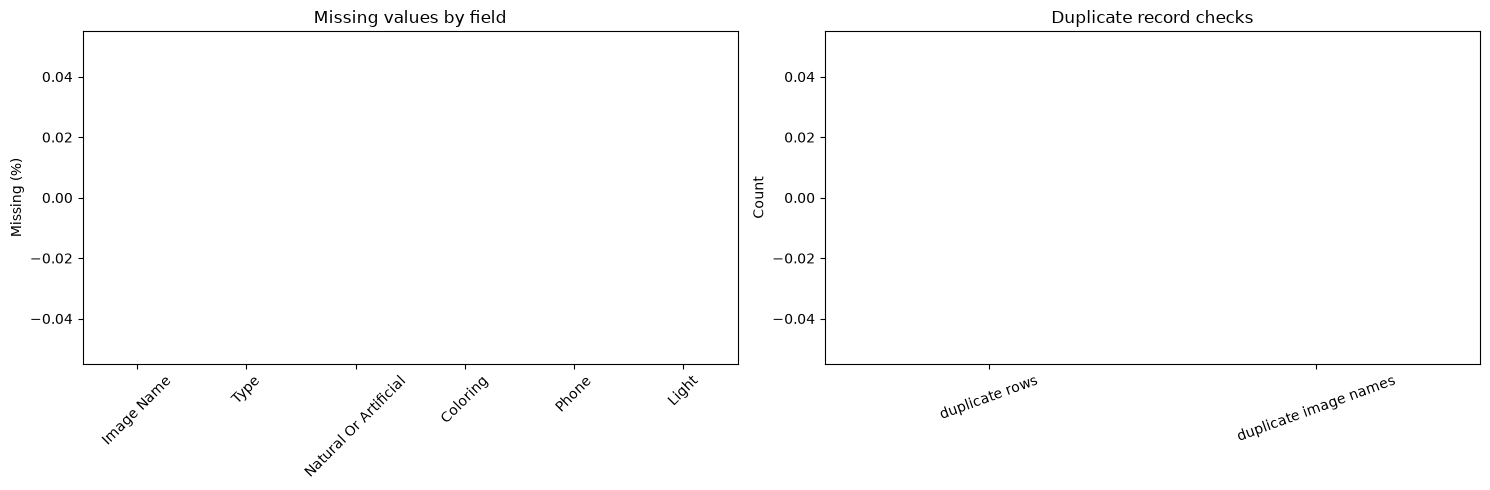

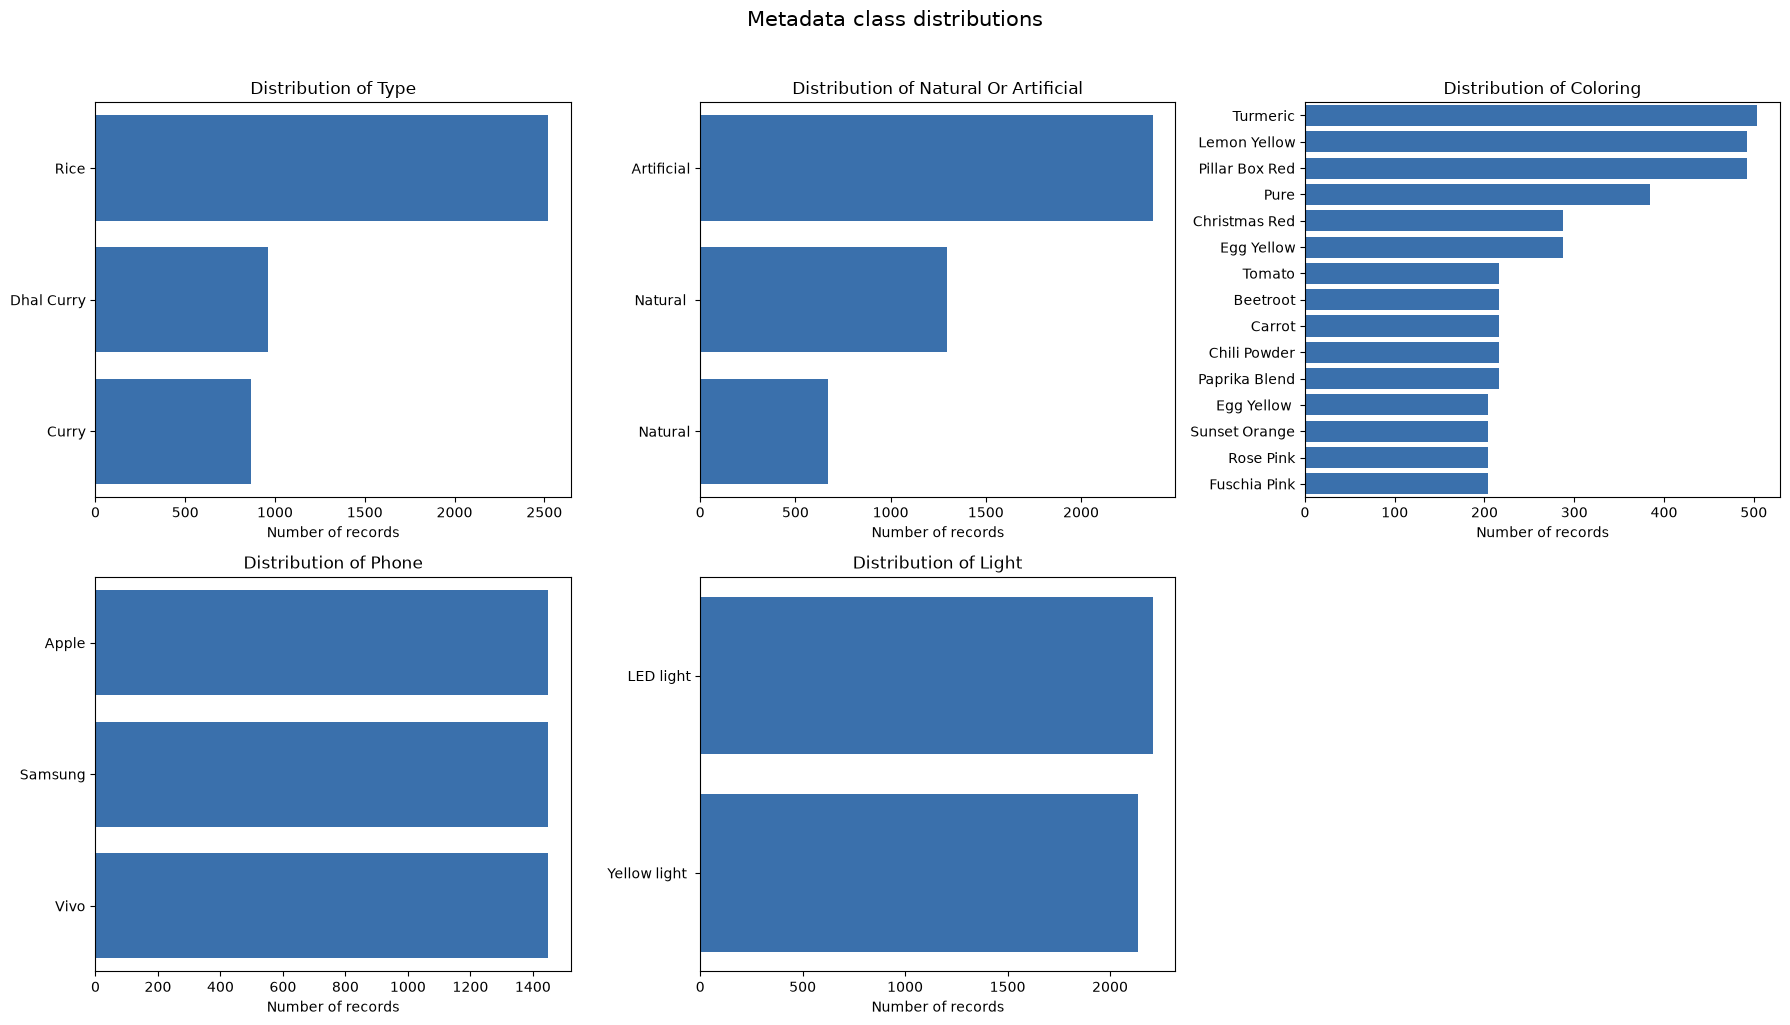

In [141]:
# 5.3 Visualise metadata quality and class distributions.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
missing_summary['missing_percent'].sort_values(ascending=False).plot(kind='bar', ax=axes[0], color='#C44536')
axes[0].set_title('Missing values by field'); axes[0].set_ylabel('Missing (%)'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)
duplicate_summary.plot(kind='bar', x='check', y='count', ax=axes[1], legend=False, color='#F28F3B')
axes[1].set_title('Duplicate record checks'); axes[1].set_ylabel('Count'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

distribution_columns = [FOOD_COLUMN, STATUS_COLUMN, COLOUR_COLUMN, PHONE_COLUMN, LIGHT_COLUMN]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for axis, column in zip(axes.flat, distribution_columns):
    order = df_raw[column].value_counts(dropna=False).index
    sns.countplot(data=df_raw, y=column, order=order, ax=axis, color='#276FBF')
    axis.set_title(f'Distribution of {column}'); axis.set_xlabel('Number of records'); axis.set_ylabel('')
axes.flat[-1].axis('off')
plt.suptitle('Metadata class distributions', y=1.02, fontsize=15)
plt.tight_layout(); plt.show()


In [142]:
# 5.4 Check repeated image names for leakage or label-conflict review.
duplicate_images = (df_raw[df_raw[IMAGE_COLUMN].duplicated(keep=False)]
                    .groupby(IMAGE_COLUMN).size()
                    .sort_values(ascending=False)
                    .rename('records'))
if duplicate_images.empty:
    print('No duplicate image names found.')
else:
    print('Repeated image names requiring review:')
    display(duplicate_images.head(20).to_frame())


No duplicate image names found.


# 6. Label Cleaning, Standardisation, and Food-to-Colouring Mapping

Whitespace is removed from all categorical fields. Equivalent labels are normalised conservatively (case and spacing only); no colour class is guessed or merged based on appearance. The original and cleaned values, encoders, and food-conditional mapping are saved.

In [143]:
# 6.1 Standardise categorical labels without inventing semantic equivalences.
def clean_label(value):
    if pd.isna(value): return np.nan
    return ' '.join(str(value).strip().split())

df = df_raw.copy()
cleaning_rows = []
for column in required_columns:
    before = sorted(df[column].dropna().astype(str).unique().tolist())
    df[column] = df[column].map(clean_label)
    after = sorted(df[column].dropna().astype(str).unique().tolist())
    cleaning_rows.append({'field': column, 'values_before': len(before), 'values_after': len(after), 'changed': before != after})

cleaning_summary = pd.DataFrame(cleaning_rows)
display(cleaning_summary)
print('Labels were standardised using whitespace trimming only; no semantic classes were merged.')


,field,values_before,values_after,changed
0,Image Name,4344,4344,False
1,Type,3,3,False
2,Natural Or Artificial,3,2,True
3,Coloring,15,14,True
4,Phone,3,3,False
5,Light,2,2,True


Labels were standardised using whitespace trimming only; no semantic classes were merged.


,records
image_exists,
Found,4344


Final class counts: {'Type': 3, 'Natural Or Artificial': 2, 'Coloring': 14}
Missing image files: 0


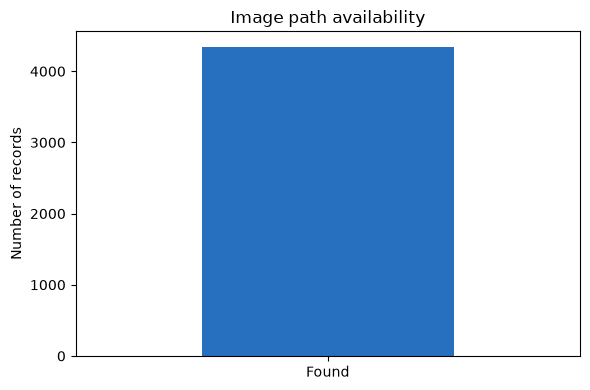

In [144]:
# 6.2 Resolve image paths and check image availability.
image_extensions = ['.jpg', '.jpeg', '.png', '.bmp', '.webp']
def resolve_image_path(value):
    raw = str(value).strip()
    candidates = [IMAGE_DIR / raw]
    if Path(raw).suffix == '':
        candidates += [IMAGE_DIR / f'{raw}{ext}' for ext in image_extensions]
    return next((path for path in candidates if path.exists()), candidates[0])

df['image_path'] = df[IMAGE_COLUMN].map(resolve_image_path)
df['image_exists'] = df['image_path'].map(Path.exists)
image_status = df['image_exists'].map({True: 'Found', False: 'Missing'}).value_counts().rename('records')
display(image_status.to_frame())
print('Final class counts:', {column: int(df[column].nunique()) for column in [FOOD_COLUMN, STATUS_COLUMN, COLOUR_COLUMN]})
print('Missing image files:', int((~df['image_exists']).sum()))

image_status.plot(kind='bar', color=['#276FBF', '#C44536'], figsize=(6, 4))
plt.title('Image path availability'); plt.ylabel('Number of records'); plt.xlabel('')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


In [145]:
# 6.3 Encode labels and save cleaned metadata artifacts.
label_mappings = {}
for column in [FOOD_COLUMN, STATUS_COLUMN, COLOUR_COLUMN]:
    labels = sorted(df[column].dropna().unique().tolist())
    label_mappings[column] = {label: index for index, label in enumerate(labels)}

with open(OUTPUT_DIR / 'label_mappings.json', 'w', encoding='utf-8') as file:
    json.dump(label_mappings, file, indent=2, ensure_ascii=False)
df.to_csv(OUTPUT_DIR / 'cleaned_metadata.csv', index=False)
print('Saved label_mappings.json and cleaned_metadata.csv')
display(pd.DataFrame([
    {'field': column, 'classes': len(mapping), 'labels': ', '.join(mapping)}
    for column, mapping in label_mappings.items()
]))


Saved label_mappings.json and cleaned_metadata.csv


,field,classes,labels
0,Type,3,"Curry, Dhal Curry, Rice"
1,Natural Or Artificial,2,"Artificial, Natural"
2,Coloring,14,"Beetroot, Carrot, Chili Powder, Christmas Red,..."


Food -> valid colouring labels:
Curry: ['Christmas Red', 'Pillar Box Red', 'Pure']
Dhal Curry: ['Egg Yellow', 'Lemon Yellow', 'Pure', 'Turmeric']
Rice: ['Beetroot', 'Carrot', 'Chili Powder', 'Egg Yellow', 'Fuschia Pink', 'Lemon Yellow', 'Paprika Blend', 'Pillar Box Red', 'Rose Pink', 'Sunset Orange', 'Tomato', 'Turmeric']


Coloring,Beetroot,Carrot,Chili Powder,Christmas Red,Egg Yellow,Fuschia Pink,Lemon Yellow,Paprika Blend,Pillar Box Red,Pure,Rose Pink,Sunset Orange,Tomato,Turmeric
Type,,,,,,,,,,,,,,
Curry,0,0,0,288,0,0,0,0,288,288,0,0,0,0
Dhal Curry,0,0,0,0,288,0,288,0,0,96,0,0,0,288
Rice,216,216,216,0,204,204,204,216,204,0,204,204,216,216


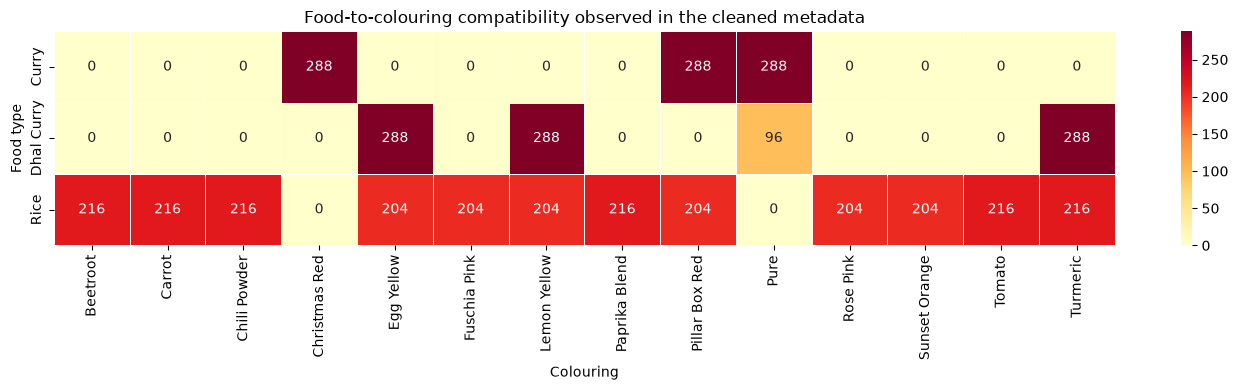

Saved food_colour_mapping.json


In [146]:
# 6.4 Build and visualise the food-to-colouring compatibility mapping.
food_colour_mapping = (df.groupby(FOOD_COLUMN)[COLOUR_COLUMN]
                       .apply(lambda values: sorted(values.dropna().unique()))
                       .to_dict())

print('Food -> valid colouring labels:')
for food, colours in food_colour_mapping.items():
    print(f'{food}: {colours}')

with open(OUTPUT_DIR / 'food_colour_mapping.json', 'w', encoding='utf-8') as file:
    json.dump(food_colour_mapping, file, indent=2, ensure_ascii=False)

compatibility_table = pd.crosstab(df[FOOD_COLUMN], df[COLOUR_COLUMN])
display(compatibility_table)
plt.figure(figsize=(14, max(4, len(compatibility_table) * 0.8)))
sns.heatmap(compatibility_table, annot=True, fmt='d', cmap='YlOrRd', linewidths=.5)
plt.title('Food-to-colouring compatibility observed in the cleaned metadata')
plt.xlabel('Colouring'); plt.ylabel('Food type'); plt.tight_layout(); plt.show()
print('Saved food_colour_mapping.json')


# 7. Dataset Audit and Visualisation

The audit checks missingness, duplicates, conflicting labels, class imbalance, and cross-tabs. All plots are exploratory diagnostics; they do not use test predictions.

In [147]:
# 7.1 Audit missing values and conflicting duplicate labels.
conflicting_images = (df.groupby(IMAGE_COLUMN)[required_columns[1:]].nunique() > 1).any(axis=1)
print('Duplicate image records with conflicting labels:', int(conflicting_images.sum()))
missing_after_cleaning = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean().mul(100).round(2),
}).sort_values('missing_count', ascending=False)
display(missing_after_cleaning.head(20))


Duplicate image records with conflicting labels: 0


,missing_count,missing_percent
Image Name,0,0.0
Type,0,0.0
Phone,0,0.0
Light,0,0.0
Natural Or Artificial,0,0.0
Coloring,0,0.0
image_path,0,0.0
image_exists,0,0.0


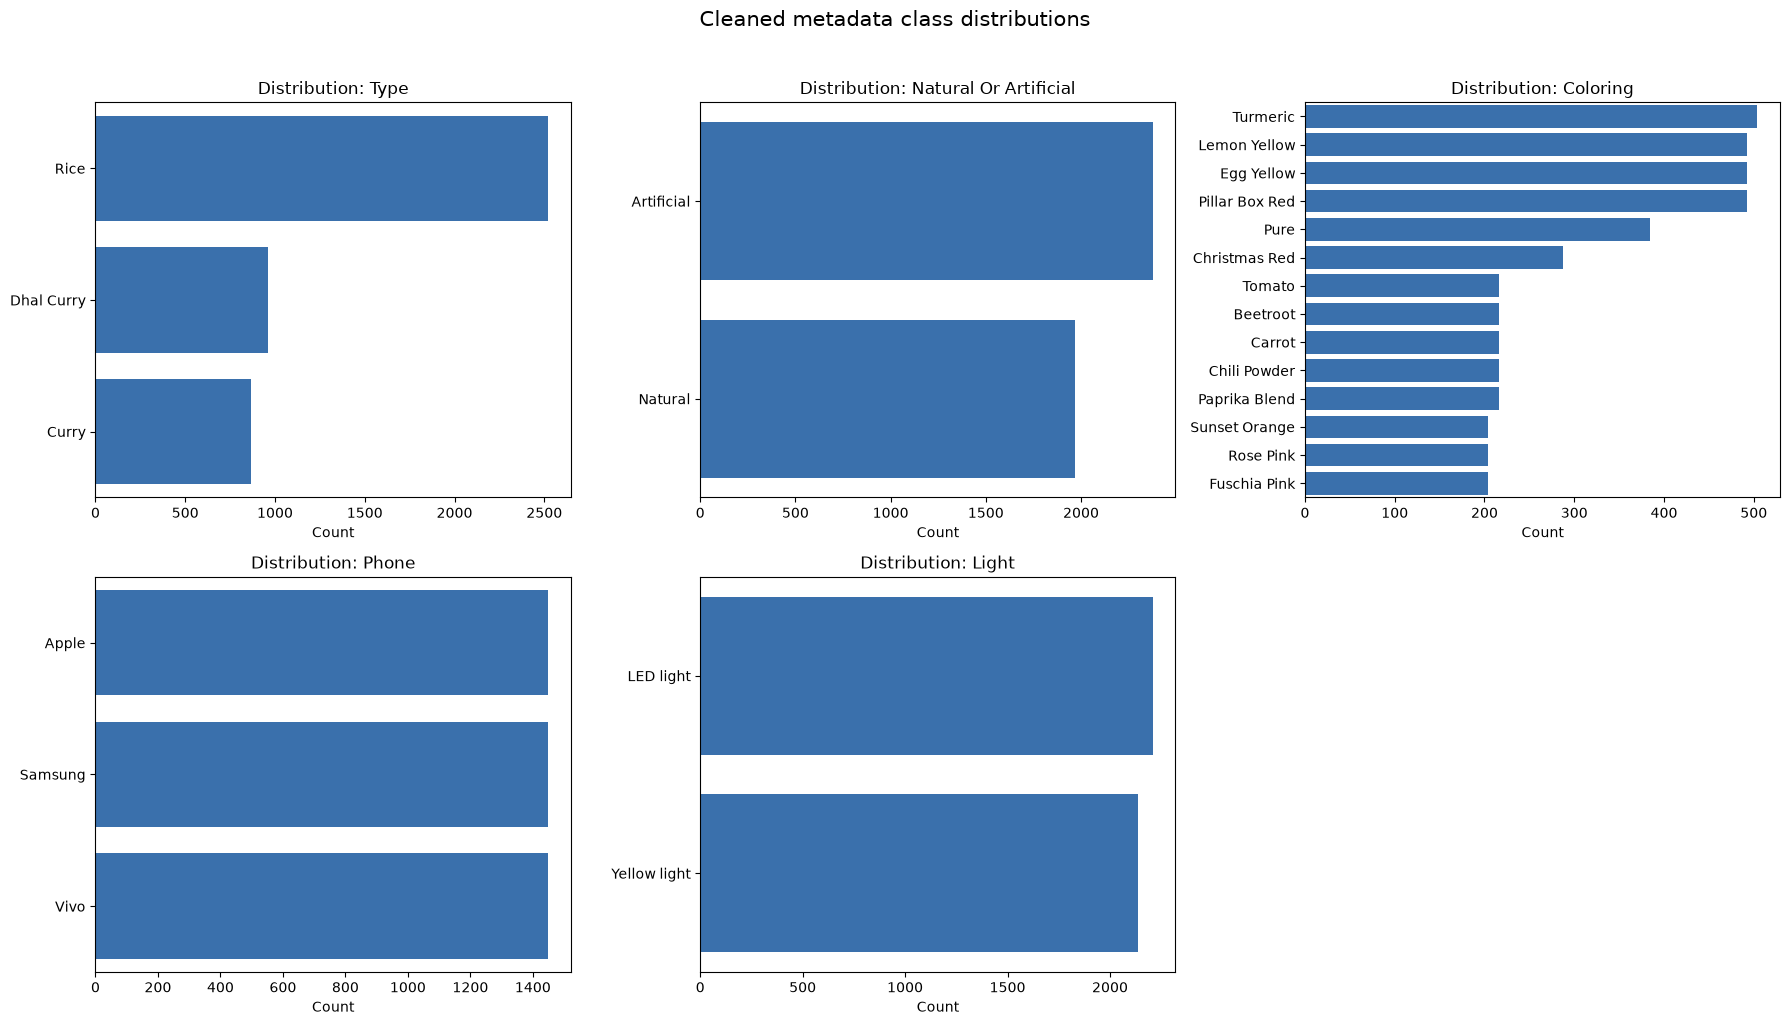

In [148]:
# 7.2 Visualise cleaned class distributions.
audit_distribution_columns = [FOOD_COLUMN, STATUS_COLUMN, COLOUR_COLUMN, PHONE_COLUMN, LIGHT_COLUMN]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for axis, column in zip(axes.flat, audit_distribution_columns):
    order = df[column].value_counts().index
    sns.countplot(data=df, y=column, order=order, ax=axis, color='#276FBF')
    axis.set_title(f'Distribution: {column}'); axis.set_xlabel('Count'); axis.set_ylabel('')
axes.flat[-1].axis('off')
plt.suptitle('Cleaned metadata class distributions', y=1.02, fontsize=15)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'class_distributions.png', dpi=160); plt.show()


Type x Coloring


Coloring,Beetroot,Carrot,Chili Powder,Christmas Red,Egg Yellow,Fuschia Pink,Lemon Yellow,Paprika Blend,Pillar Box Red,Pure,Rose Pink,Sunset Orange,Tomato,Turmeric
Type,,,,,,,,,,,,,,
Curry,0,0,0,288,0,0,0,0,288,288,0,0,0,0
Dhal Curry,0,0,0,0,288,0,288,0,0,96,0,0,0,288
Rice,216,216,216,0,204,204,204,216,204,0,204,204,216,216


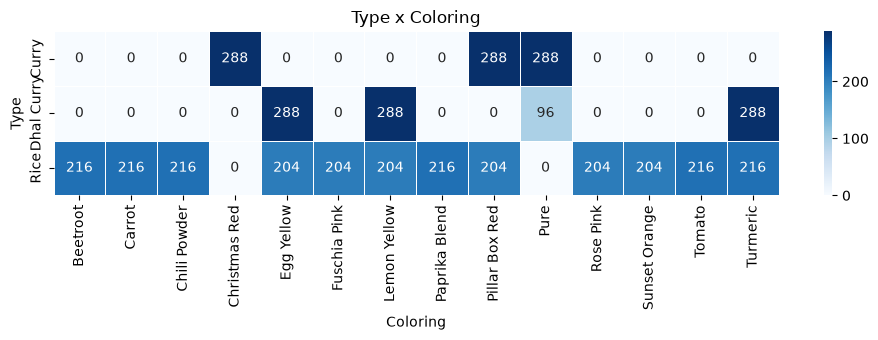

Type x Natural Or Artificial


Natural Or Artificial,Artificial,Natural
Type,,
Curry,576,288
Dhal Curry,576,384
Rice,1224,1296


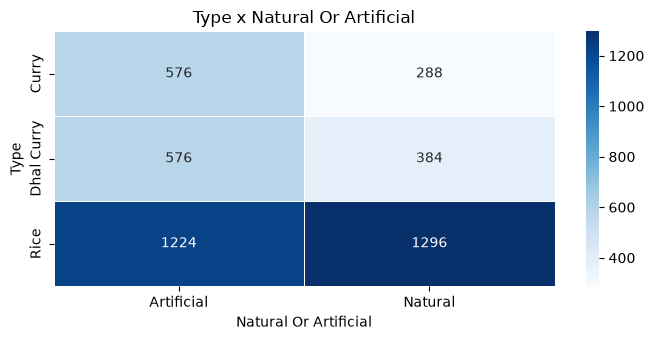

Type x Phone


Phone,Apple,Samsung,Vivo
Type,,,
Curry,288,288,288
Dhal Curry,320,320,320
Rice,840,840,840


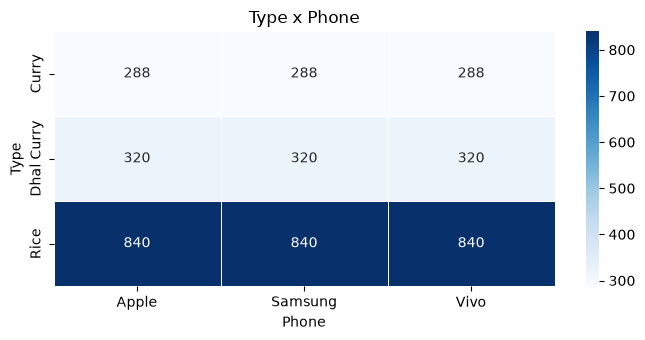

Type x Light


Light,LED light,Yellow light
Type,,
Curry,432,432
Dhal Curry,480,480
Rice,1296,1224


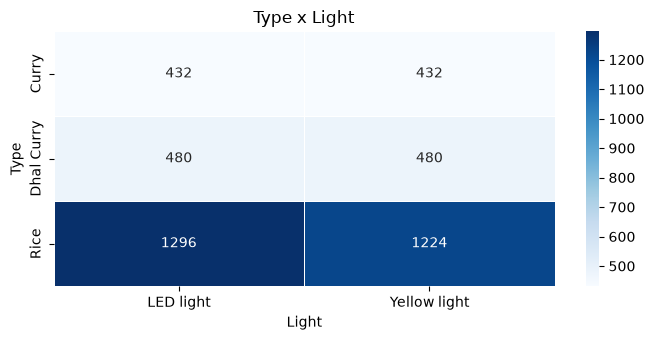

Phone x Light


Light,LED light,Yellow light
Phone,,
Apple,736,712
Samsung,736,712
Vivo,736,712


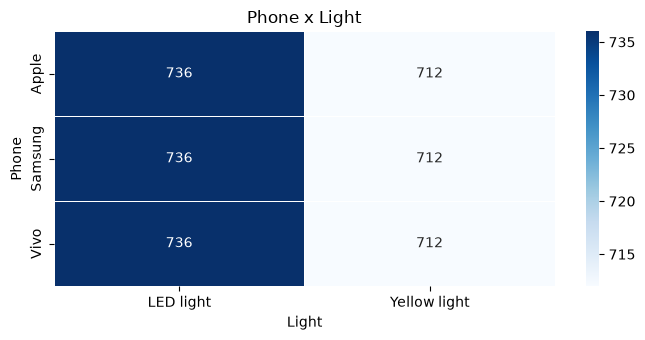

Coloring x Phone


Phone,Apple,Samsung,Vivo
Coloring,,,
Beetroot,72,72,72
Carrot,72,72,72
Chili Powder,72,72,72
Christmas Red,96,96,96
Egg Yellow,164,164,164
Fuschia Pink,68,68,68
Lemon Yellow,164,164,164
Paprika Blend,72,72,72
Pillar Box Red,164,164,164


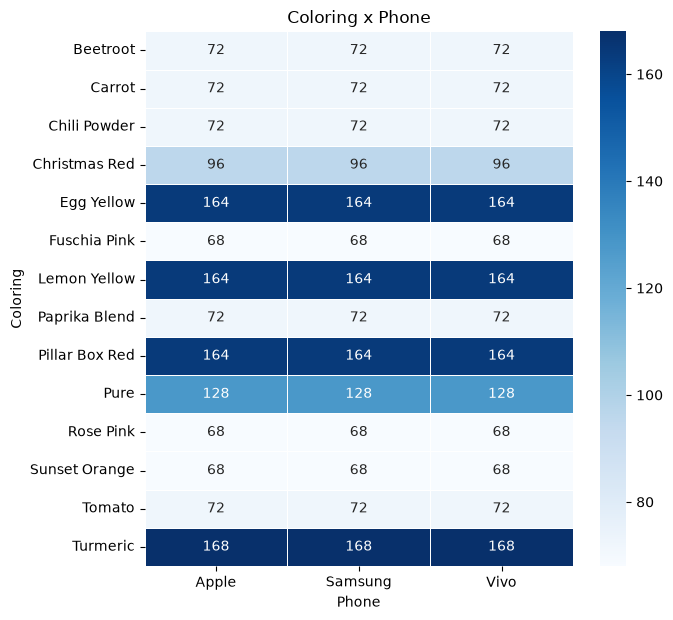

Coloring x Light


Light,LED light,Yellow light
Coloring,,
Beetroot,108,108
Carrot,108,108
Chili Powder,108,108
Christmas Red,144,144
Egg Yellow,252,240
Fuschia Pink,108,96
Lemon Yellow,252,240
Paprika Blend,108,108
Pillar Box Red,252,240


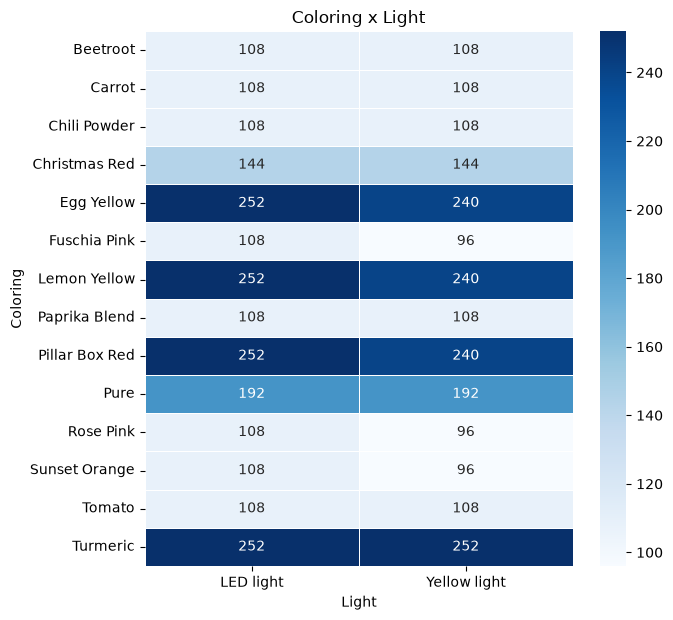

In [149]:
# 7.3 Display cross-tabulation tables and heatmaps.
cross_tabs = [
    (FOOD_COLUMN, COLOUR_COLUMN), (FOOD_COLUMN, STATUS_COLUMN),
    (FOOD_COLUMN, PHONE_COLUMN), (FOOD_COLUMN, LIGHT_COLUMN),
    (PHONE_COLUMN, LIGHT_COLUMN), (COLOUR_COLUMN, PHONE_COLUMN),
    (COLOUR_COLUMN, LIGHT_COLUMN),
]
for left, right in cross_tabs:
    table = pd.crosstab(df[left], df[right])
    print(f'{left} x {right}')
    display(table)
    plt.figure(figsize=(max(7, len(table.columns) * .7), max(3.5, len(table) * .45)))
    sns.heatmap(table, annot=True, fmt='d', cmap='Blues', linewidths=.5)
    plt.title(f'{left} x {right}')
    plt.xlabel(right); plt.ylabel(left); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'crosstab_{left}_{right}.png', dpi=150); plt.show()


,Type,Coloring,records
0,Curry,Christmas Red,288
1,Curry,Pillar Box Red,288
2,Curry,Pure,288
3,Dhal Curry,Egg Yellow,288
4,Dhal Curry,Lemon Yellow,288
5,Dhal Curry,Pure,96
6,Dhal Curry,Turmeric,288
7,Rice,Beetroot,216
8,Rice,Carrot,216
9,Rice,Chili Powder,216


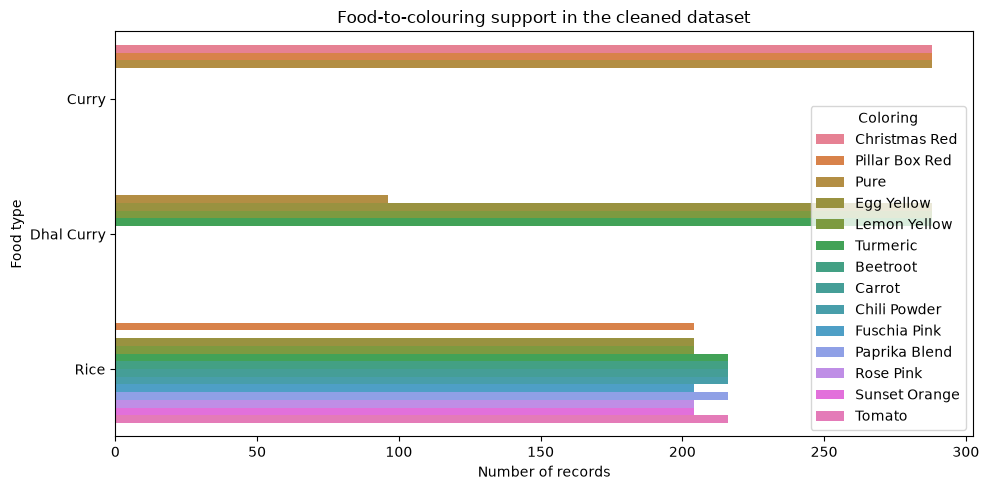

In [150]:
# 7.4 Visualise observed food-to-colouring support.
mapping_table = (df.groupby([FOOD_COLUMN, COLOUR_COLUMN]).size()
                .reset_index(name='records'))
display(mapping_table.sort_values([FOOD_COLUMN, COLOUR_COLUMN]))
plt.figure(figsize=(10, 5))
sns.barplot(data=mapping_table, y=FOOD_COLUMN, x='records', hue=COLOUR_COLUMN, orient='h')
plt.title('Food-to-colouring support in the cleaned dataset')
plt.xlabel('Number of records'); plt.ylabel('Food type'); plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'food_colour_mapping.png', dpi=160); plt.show()


# 8. Image Validation and Sample Inspection

Images are opened with Pillow to identify missing/corrupt files and record dimensions/aspect ratios. The sample grid is stratified by metadata where possible, allowing visual inspection of food, status, phone, and light.

In [151]:
# 8.1 Validate every referenced image and record its dimensions.
image_records, corrupt_images = [], []
for path in tqdm(df.loc[df.image_exists, 'image_path'], desc='Validating images'):
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            width, height = image.size
        image_records.append((str(path), width, height, width / height))
    except Exception as error:
        corrupt_images.append({'path': str(path), 'error': repr(error)})

image_stats = pd.DataFrame(image_records, columns=['image_path', 'width', 'height', 'aspect_ratio'])
print('Valid images:', len(image_stats), '| Corrupt images:', len(corrupt_images))
display(pd.DataFrame(corrupt_images).head(5))


Validating images: 100%|██████████| 4344/4344 [00:04<00:00, 914.42it/s] 

Valid images: 4344 | Corrupt images: 0


""


,width,height,aspect_ratio
count,4344.000000,4344.000000,4344.000000
mean,2044.847606,1976.194521,1.089480
std,561.905574,553.838917,0.341628
min,542.000000,536.000000,0.428446
25%,1576.000000,1553.000000,0.786844
50%,1992.000000,1956.000000,1.080539
75%,2451.000000,2366.000000,1.319493
max,4032.000000,4080.000000,2.513035


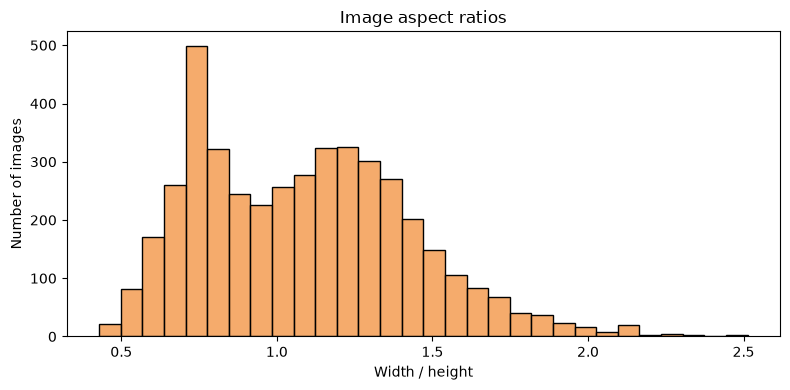

In [152]:
# 8.2 Summarise image dimensions and visualise aspect ratios.
display(image_stats.describe())
plt.figure(figsize=(8, 4))
sns.histplot(image_stats['aspect_ratio'], bins=30, color='#F28F3B')
plt.title('Image aspect ratios'); plt.xlabel('Width / height'); plt.ylabel('Number of images')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'aspect_ratios.png', dpi=150); plt.show()


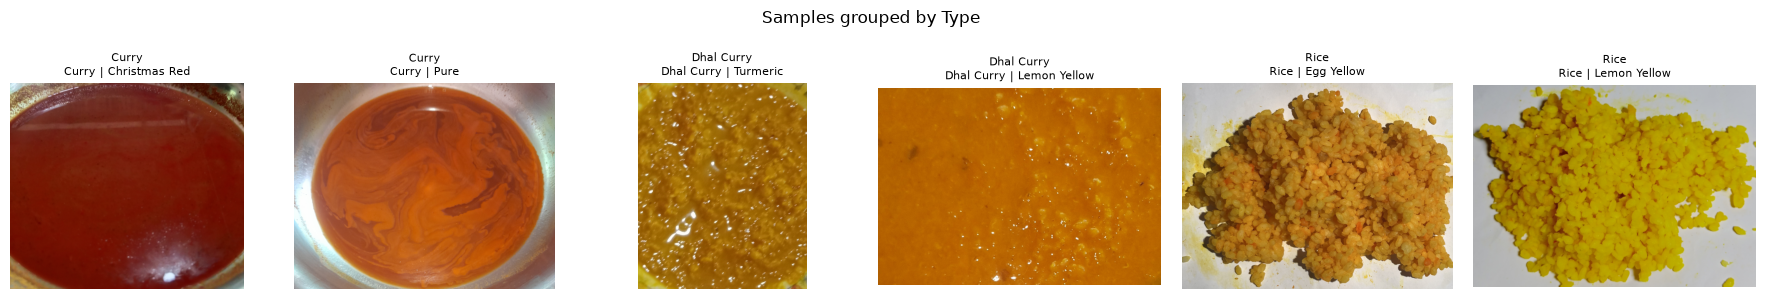

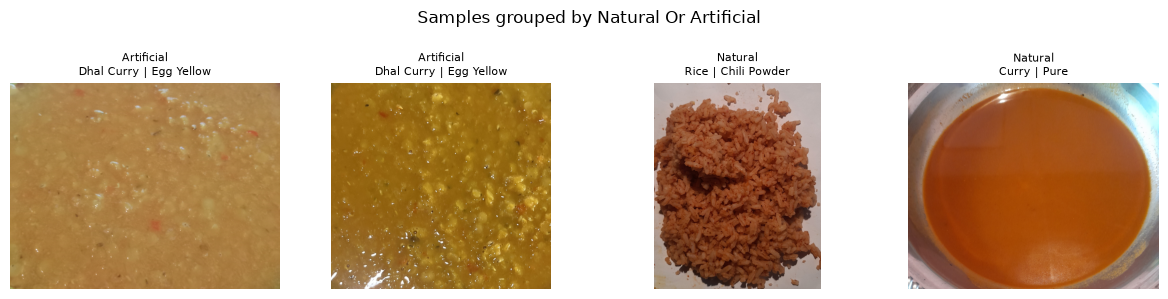

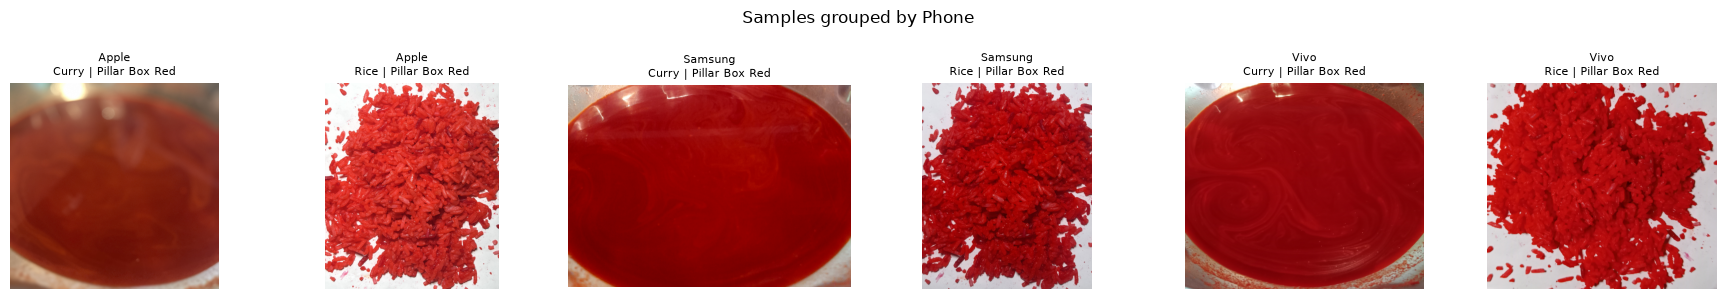

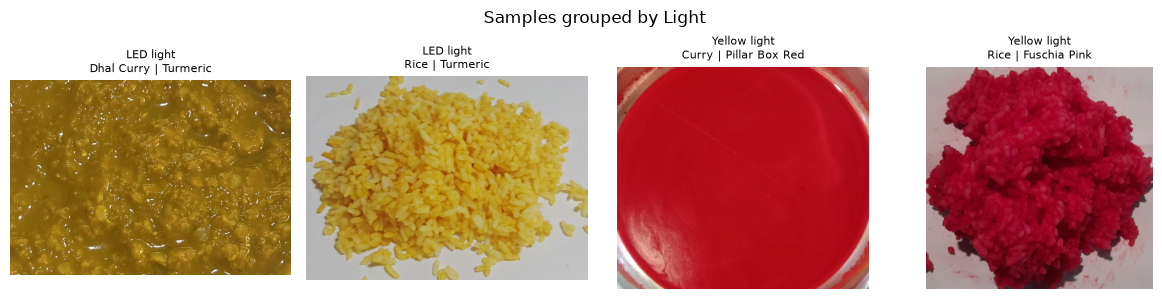

In [153]:
# 8.3 Display representative images grouped by metadata category.
for category in [FOOD_COLUMN, STATUS_COLUMN, PHONE_COLUMN, LIGHT_COLUMN]:
    sample_parts = []
    for _, part in df[df.image_exists].groupby(category):
        sample_parts.append(part.sample(min(2, len(part)), random_state=SEED))
    sample = pd.concat(sample_parts, ignore_index=True).head(8)
    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    axes = np.atleast_1d(axes)
    for axis, (_, row) in zip(axes, sample.iterrows()):
        axis.imshow(Image.open(row.image_path).convert('RGB'))
        axis.axis('off')
        axis.set_title(f"{row[category]}\n{row[FOOD_COLUMN]} | {row[COLOUR_COLUMN]}", fontsize=8)
    plt.suptitle(f'Samples grouped by {category}')
    plt.tight_layout(); plt.show()


# 9. Splitting Strategy

A composite stratification key combines food, status, colouring, phone, and light. Rare composite strata are assigned to a fallback key before a reproducible 70/15/15 split. This keeps both lighting conditions in development whenever the data supports it and prevents the same image path from crossing splits. The unseen-device experiment is configured from discovered device values rather than hardcoded names.

In [154]:
# 9.1 Remove unusable records and prepare the stratification key.
df_model = df[df.image_exists].copy()
df_model = df_model.dropna(subset=required_columns)
df_model = df_model.drop_duplicates(subset=['image_path']).reset_index(drop=True)

df_model['strata'] = df_model[required_columns[1:]].astype(str).agg('|'.join, axis=1)
strata_counts = df_model['strata'].value_counts()
rare_strata = strata_counts[strata_counts < 3].index
df_model.loc[df_model['strata'].isin(rare_strata), 'strata'] = 'RARE'

print('Usable records:', len(df_model))
print('Removed records:', len(df) - len(df_model))
print('Stratification groups:', df_model['strata'].nunique())
display(df_model['strata'].value_counts().head(15).to_frame('records'))


Usable records: 4344
Removed records: 0
Stratification groups: 114


,records
strata,
Curry|Artificial|Christmas Red|Apple|LED light,48
Curry|Artificial|Christmas Red|Apple|Yellow light,48
Curry|Artificial|Christmas Red|Samsung|LED light,48
Curry|Artificial|Christmas Red|Samsung|Yellow light,48
Curry|Artificial|Christmas Red|Vivo|LED light,48
Curry|Artificial|Christmas Red|Vivo|Yellow light,48
Curry|Artificial|Pillar Box Red|Apple|LED light,48
Curry|Artificial|Pillar Box Red|Apple|Yellow light,48
Curry|Artificial|Pillar Box Red|Samsung|LED light,48


In [155]:
# 9.2 Create reproducible 70/15/15 train, validation, and test splits.
train_df, temp_df = train_test_split(
    df_model,
    test_size=0.30,
    random_state=SEED,
    stratify=df_model['strata'],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df['strata'],
)

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Test:', len(test_df))
print('Total:', len(train_df) + len(val_df) + len(test_df))


Train: 3040
Validation: 652
Test: 652
Total: 4344


,train,validation,test
Type,,,
Rice,1750,384,386
Dhal Curry,678,142,140
Curry,612,126,126


Train lighting: {'LED light': 1545, 'Yellow light': 1495}
Validation lighting: {'LED light': 332, 'Yellow light': 320}
Test lighting: {'LED light': 331, 'Yellow light': 321}
Train devices: {'Samsung': 1015, 'Vivo': 1013, 'Apple': 1012}
Validation devices: {'Apple': 221, 'Vivo': 216, 'Samsung': 215}
Test devices: {'Vivo': 219, 'Samsung': 218, 'Apple': 215}
Evaluation compatibility mapping uses training data only.


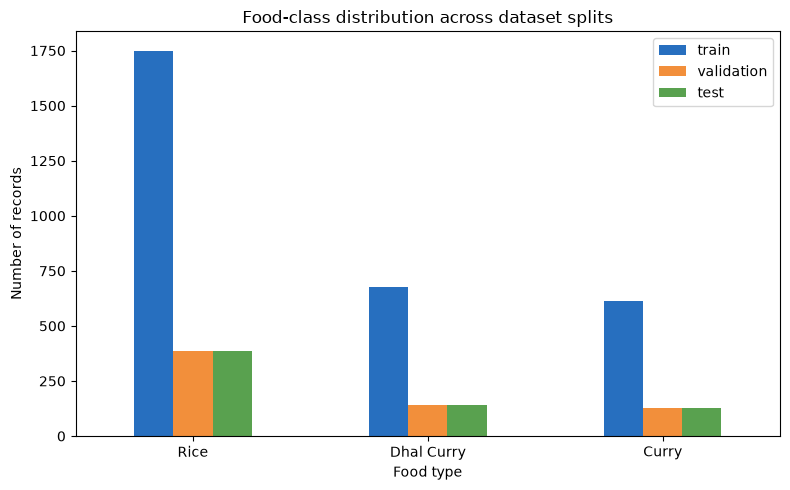

In [156]:
# 9.3 Check split balance, define training-only compatibility, and save metadata files.
split_summary = pd.DataFrame({
    'train': train_df[FOOD_COLUMN].value_counts(),
    'validation': val_df[FOOD_COLUMN].value_counts(),
    'test': test_df[FOOD_COLUMN].value_counts(),
}).fillna(0).astype(int)
display(split_summary)

print('Train lighting:', train_df[LIGHT_COLUMN].value_counts().to_dict())
print('Validation lighting:', val_df[LIGHT_COLUMN].value_counts().to_dict())
print('Test lighting:', test_df[LIGHT_COLUMN].value_counts().to_dict())
print('Train devices:', train_df[PHONE_COLUMN].value_counts().to_dict())
print('Validation devices:', val_df[PHONE_COLUMN].value_counts().to_dict())
print('Test devices:', test_df[PHONE_COLUMN].value_counts().to_dict())

train_food_colour_mapping = (
    train_df.groupby(FOOD_COLUMN)[COLOUR_COLUMN]
    .apply(lambda values: sorted(values.dropna().unique()))
    .to_dict()
)
print('Evaluation compatibility mapping uses training data only.')

train_df.to_csv(OUTPUT_DIR / 'train_metadata.csv', index=False)
val_df.to_csv(OUTPUT_DIR / 'validation_metadata.csv', index=False)
test_df.to_csv(OUTPUT_DIR / 'test_metadata.csv', index=False)

split_summary.plot(kind='bar', figsize=(8, 5), color=['#276FBF', '#F28F3B', '#59A14F'])
plt.title('Food-class distribution across dataset splits')
plt.ylabel('Number of records'); plt.xlabel('Food type')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'split_class_balance.png', dpi=160); plt.show()

In [157]:
# 9.4 Prepare the strict unseen-device generalisation split.
# This split is independent from the standard test set: only normal train/validation
# rows are eligible for unseen-device training, and only normal test rows are used
# for the held-out-device test.
devices = sorted(df_model[PHONE_COLUMN].unique().tolist())
unseen_device = devices[-1]
print('Discovered devices:', devices)
print('Held-out device:', unseen_device)

unseen_train_pool = pd.concat([
    train_df[train_df[PHONE_COLUMN] != unseen_device],
    val_df[val_df[PHONE_COLUMN] != unseen_device],
], ignore_index=True)
unseen_test_df = test_df[test_df[PHONE_COLUMN] == unseen_device].copy()
unseen_train_df, unseen_val_df = train_test_split(
    unseen_train_pool,
    test_size=0.15,
    random_state=SEED,
    stratify=unseen_train_pool[FOOD_COLUMN],
)

print('Unseen-device train:', len(unseen_train_df))
print('Unseen-device validation:', len(unseen_val_df))
print('Unseen-device test:', len(unseen_test_df))
print('Unseen test device values:', unseen_test_df[PHONE_COLUMN].unique().tolist())

unseen_train_df.to_csv(OUTPUT_DIR / 'unseen_device_train_metadata.csv', index=False)
unseen_val_df.to_csv(OUTPUT_DIR / 'unseen_device_validation_metadata.csv', index=False)
unseen_test_df.to_csv(OUTPUT_DIR / 'unseen_device_test_metadata.csv', index=False)


Discovered devices: ['Apple', 'Samsung', 'Vivo']
Held-out device: Vivo
Unseen-device train: 2093
Unseen-device validation: 370
Unseen-device test: 219
Unseen test device values: ['Vivo']


# 10. RGB Preprocessing, Colour-Preserving Augmentation, Dataset, and DataLoader

Augmentation avoids hue and saturation changes because colour is a target. Training uses resize/crop, horizontal flip, small rotation, mild brightness/contrast, and mild blur. Validation and test use deterministic resize and centre crop. ImageNet normalisation matches pretrained torchvision backbones.

In [158]:
# 10.1 Create label encoders from the cleaned dataset.
food_labels = sorted(df_model[FOOD_COLUMN].unique())
status_labels = sorted(df_model[STATUS_COLUMN].unique())
colour_labels = sorted(df_model[COLOUR_COLUMN].unique())

food_to_id = {label: index for index, label in enumerate(food_labels)}
status_to_id = {label: index for index, label in enumerate(status_labels)}
colour_to_id = {label: index for index, label in enumerate(colour_labels)}

num_food = len(food_labels)
num_status = len(status_labels)
num_colour = len(colour_labels)

label_summary = pd.DataFrame({
    'food_classes': [num_food],
    'status_classes': [num_status],
    'colour_classes': [num_colour],
})
display(label_summary)
print('Food labels:', food_labels)
print('Status labels:', status_labels)
print('Colour labels:', colour_labels)


,food_classes,status_classes,colour_classes
0,3,2,14


Food labels: ['Curry', 'Dhal Curry', 'Rice']
Status labels: ['Artificial', 'Natural']
Colour labels: ['Beetroot', 'Carrot', 'Chili Powder', 'Christmas Red', 'Egg Yellow', 'Fuschia Pink', 'Lemon Yellow', 'Paprika Blend', 'Pillar Box Red', 'Pure', 'Rose Pink', 'Sunset Orange', 'Tomato', 'Turmeric']


In [159]:
# 10.2 Define colour-preserving training and evaluation transforms.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 24, IMAGE_SIZE + 24)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0, hue=0),
    transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 0.6))], p=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

print('Training transform:', train_transform)
print('Evaluation transform:', eval_transform)


Training transform: Compose(
    Resize(size=(248, 248), interpolation=bilinear, max_size=None, antialias=True)
    RandomCrop(size=(224, 224), padding=None)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-8.0, 8.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    RandomApply(
    p=0.1
    GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 0.6))
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Evaluation transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [160]:
# 10.3 Define the dataset and create the three DataLoaders.
class FoodDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = Image.open(row.image_path).convert('RGB')
        return {
            'image': self.transform(image),
            'food': food_to_id[row[FOOD_COLUMN]],
            'status': status_to_id[row[STATUS_COLUMN]],
            'colour': colour_to_id[row[COLOUR_COLUMN]],
            'path': str(row.image_path),
            'device': row[PHONE_COLUMN],
            'light': row[LIGHT_COLUMN],
        }

train_loader = DataLoader(
    FoodDataset(train_df, train_transform),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    FoodDataset(val_df, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    FoodDataset(test_df, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print('Train batches:', len(train_loader))
print('Validation batches:', len(val_loader))
print('Test batches:', len(test_loader))


Train batches: 190
Validation batches: 41
Test batches: 41


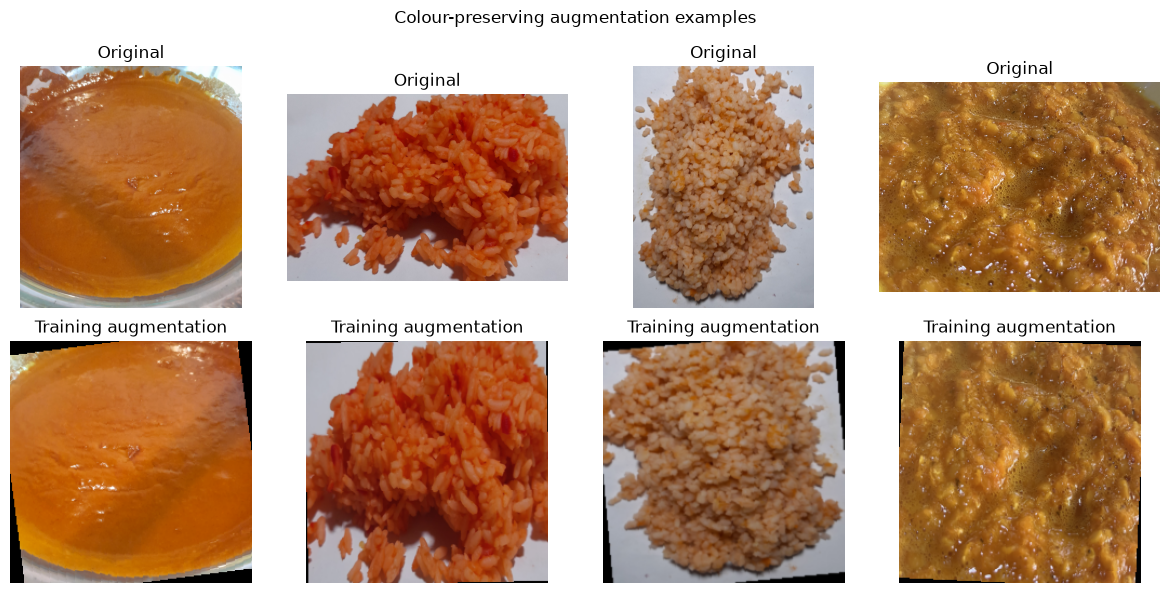

In [161]:
# 10.4 Visualise the actual colour-preserving training augmentation.
example = train_df.sample(min(4, len(train_df)), random_state=SEED)
fig, axes = plt.subplots(2, len(example), figsize=(12, 6))
axes = np.atleast_2d(axes)

for column, (_, row) in enumerate(example.iterrows()):
    original = Image.open(row.image_path).convert('RGB')
    augmented = train_transform(original).permute(1, 2, 0).numpy()
    augmented = augmented * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    axes[0, column].imshow(original)
    axes[0, column].axis('off')
    axes[0, column].set_title('Original')
    axes[1, column].imshow(np.clip(augmented, 0, 1))
    axes[1, column].axis('off')
    axes[1, column].set_title('Training augmentation')

plt.suptitle('Colour-preserving augmentation examples')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'augmentation_examples.png', dpi=150)
plt.show()


# 11. Models: Shared Multi-Task Interface, Baselines, and Mona

All models return the same three logits. The global colour ablation receives only image features; the proposed model concatenates image features with soft food probabilities. Full Swin fine-tuning is available through torchvision. Mona is resolved through the installed official PEFT API and is never silently substituted.

In [162]:
# 11.1 Shared multi-task prediction heads.
class MultiTaskHeads(nn.Module):
    def __init__(self, feature_dim, conditional=True):
        super().__init__()
        self.conditional = conditional
        self.food_head = nn.Linear(feature_dim, num_food)
        self.status_head = nn.Linear(feature_dim, num_status)
        colour_input = feature_dim + num_food if conditional else feature_dim
        self.food_projection = (
            nn.Sequential(nn.Linear(num_food, num_food), nn.ReLU())
            if conditional else None
        )
        self.colour_head = nn.Sequential(
            nn.Linear(colour_input, feature_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(feature_dim // 2, num_colour),
        )

    def forward(self, features):
        food_logits = self.food_head(features)
        status_logits = self.status_head(features)
        food_probabilities = torch.softmax(food_logits, dim=1)
        colour_input = torch.cat([features, self.food_projection(food_probabilities)], dim=1) if self.conditional else features
        return {
            'food': food_logits,
            'status': status_logits,
            'colour': self.colour_head(colour_input),
        }


In [163]:
# 11.2 Shared model wrapper used by every backbone.
class MultiTaskModel(nn.Module):
    def __init__(self, backbone, feature_dim, conditional=True):
        super().__init__()
        self.backbone = backbone
        self.heads = MultiTaskHeads(feature_dim, conditional)

    def forward(self, images):
        features = self.backbone(images)
        return self.heads(features)


In [164]:
# 11.3 Baseline 1: EfficientNetV2-S with soft food conditioning.
def build_efficientnet_v2_s():
    weights = models.EfficientNet_V2_S_Weights.DEFAULT
    backbone = models.efficientnet_v2_s(weights=weights)
    feature_dim = backbone.classifier[1].in_features
    backbone.classifier = nn.Identity()
    return MultiTaskModel(backbone, feature_dim, conditional=True).to(DEVICE)


In [165]:
# 11.4 Baseline 2: full Swin-T fine-tuning with soft food conditioning.
def build_swin_full():
    weights = models.Swin_T_Weights.DEFAULT
    backbone = models.swin_t(weights=weights)
    feature_dim = backbone.head.in_features
    backbone.head = nn.Identity()
    return MultiTaskModel(backbone, feature_dim, conditional=True).to(DEVICE)


In [166]:
# 11.7 Proposed model: the official Mona adapter ported to torchvision Swin-T.
from types import MethodType
from torchvision.models.swin_transformer import SwinTransformerBlock


class MonaOp(nn.Module):
    """Official Mona multi-kernel depthwise convolution operator."""

    def __init__(self, in_features):
        super().__init__()
        self.conv1 = nn.Conv2d(in_features, in_features, 3, padding=1, groups=in_features)
        self.conv2 = nn.Conv2d(in_features, in_features, 5, padding=2, groups=in_features)
        self.conv3 = nn.Conv2d(in_features, in_features, 7, padding=3, groups=in_features)
        self.projector = nn.Conv2d(in_features, in_features, 1)

    def forward(self, x):
        identity = x
        x = (self.conv1(x) + self.conv2(x) + self.conv3(x)) / 3.0 + identity
        return x + self.projector(x)


class MonaAdapter(nn.Module):
    """Official Mona adapter operating on torchvision's B, H, W, C features."""

    def __init__(self, in_dim):
        super().__init__()
        self.project1 = nn.Linear(in_dim, 64)
        self.adapter_conv = MonaOp(64)
        self.project2 = nn.Linear(64, in_dim)
        self.norm = nn.LayerNorm(in_dim)
        self.dropout = nn.Dropout(0.1)
        self.gamma = nn.Parameter(torch.ones(in_dim) * 1e-6)
        self.gammax = nn.Parameter(torch.ones(in_dim))

    def forward(self, x):
        batch_size, height, width, channels = x.shape
        identity = x
        x = self.norm(x) * self.gamma + x * self.gammax
        x = self.project1(x).permute(0, 3, 1, 2)
        x = self.adapter_conv(x).permute(0, 2, 3, 1)
        x = self.project2(F.gelu(x))
        return identity + self.dropout(x)


def mona_swin_block_forward(self, x):
    """Match the reference Mona insertion around torchvision's Swin block."""
    x = x + self.stochastic_depth(self.attn(self.norm1(x)))
    x = self.my_module_1(x)
    identity = x
    x = self.mlp(self.norm2(x))
    x = identity + self.stochastic_depth(x)
    return self.my_module_2(x)


def build_mona_proposed():
    weights = models.Swin_T_Weights.DEFAULT
    backbone = models.swin_t(weights=weights)
    feature_dim = backbone.head.in_features
    backbone.head = nn.Identity()

    blocks = [
        module
        for module in backbone.features.modules()
        if isinstance(module, SwinTransformerBlock)
    ]
    if not blocks:
        raise RuntimeError('Could not locate torchvision SwinTransformerBlock modules.')

    for block in blocks:
        block.my_module_1 = MonaAdapter(block.norm1.normalized_shape[0])
        block.my_module_2 = MonaAdapter(block.norm2.normalized_shape[0])
        block.forward = MethodType(mona_swin_block_forward, block)

    # The official implementation freezes the pretrained backbone and trains Mona.
    for parameter in backbone.parameters():
        parameter.requires_grad = False
    for block in blocks:
        for parameter in block.my_module_1.parameters():
            parameter.requires_grad = True
        for parameter in block.my_module_2.parameters():
            parameter.requires_grad = True

    return MultiTaskModel(backbone, feature_dim, conditional=True).to(DEVICE)


In [167]:
# 11.5 Register the three final study models.
MODEL_REGISTRY = {
    'efficientnet_v2_s': build_efficientnet_v2_s,
    'swin_full': build_swin_full,
    'mona_proposed': build_mona_proposed,
}


def build_model(name):
    if name not in MODEL_REGISTRY:
        raise KeyError(f'Unknown final study model: {name}')
    return MODEL_REGISTRY[name]()

assert set(MODEL_REGISTRY) == {'efficientnet_v2_s', 'swin_full', 'mona_proposed'}
print('Final study model builders:', list(MODEL_REGISTRY))


Final study model builders: ['efficientnet_v2_s', 'swin_full', 'mona_proposed']


## Mona implementation integrity note

The linked repository, `https://github.com/Leiyi-HU/mona`, is the official CVPR 2025 Mona implementation by Yin et al. It is an OpenMMLab/MMClassification project and does not provide `peft.MonaConfig`. This notebook ports its classification adapter faithfully: `MonaOp` uses depthwise 3x3, 5x5, and 7x7 convolutions, and two `MonaAdapter` modules are inserted into every torchvision Swin-T block. The pretrained Swin backbone is frozen and only the Mona modules and task heads are trained. The parameter report records this split.

# 12. Losses, Optimiser, Scheduler, Early Stopping, and Training

Cross-entropy is weighted per task using training-only class frequencies. Equal task weights are the default; configurable weights support a documented sensitivity run. Validation score is the mean of food, status, and colour macro F1, so no single head controls checkpoint selection. AdamW and ReduceLROnPlateau are used, with gradient clipping and mixed precision on CUDA.

In [168]:
# 12.1 Define class weights and task losses.
def class_weights(frame, column, mapping):
    counts = frame[column].map(mapping).value_counts()
    counts = counts.reindex(range(len(mapping)), fill_value=0).values
    weights = counts.sum() / np.maximum(counts, 1)
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

loss_functions = {
    'food': nn.CrossEntropyLoss(weight=class_weights(train_df, FOOD_COLUMN, food_to_id)),
    'status': nn.CrossEntropyLoss(weight=class_weights(train_df, STATUS_COLUMN, status_to_id)),
    'colour': nn.CrossEntropyLoss(weight=class_weights(train_df, COLOUR_COLUMN, colour_to_id)),
}

TASK_WEIGHTS = {
    'food': 1.0,
    'status': 1.0,
    'colour': 1.0,
}

print('Task weights:', TASK_WEIGHTS)


Task weights: {'food': 1.0, 'status': 1.0, 'colour': 1.0}


In [169]:
# 12.2 Calculate the weighted multi-task loss.
def multitask_loss(outputs, batch):
    losses = {}
    for head in ['food', 'status', 'colour']:
        losses[head] = loss_functions[head](outputs[head], batch[head].to(DEVICE))
    total_loss = sum(TASK_WEIGHTS[head] * losses[head] for head in losses)
    return total_loss, losses


In [170]:
# 12.3 Prediction collection and complete classification metrics.
def parameter_report(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    return {
        'total_parameters': total,
        'trainable_parameters': trainable,
        'frozen_parameters': total - trainable,
        'trainable_percent': 100 * trainable / max(total, 1),
    }


def collect_predictions(model, loader):
    model.eval()
    probabilities = {'food': [], 'status': [], 'colour': []}
    targets = {'food': [], 'status': [], 'colour': []}
    metadata = []

    with torch.no_grad():
        for batch in loader:
            outputs = model(batch['image'].to(DEVICE))
            if set(outputs) != {'food', 'status', 'colour'}:
                raise RuntimeError('Every model must return food, status, and colour heads.')
            for head in probabilities:
                probabilities[head].append(torch.softmax(outputs[head], dim=1).cpu().numpy())
                targets[head].append(batch[head].numpy())
            metadata.extend([
                {key: batch[key][index] for key in ['path', 'device', 'light']}
                for index in range(len(batch['path']))
            ])

    probabilities = {head: np.concatenate(values) for head, values in probabilities.items()}
    targets = {head: np.concatenate(values) for head, values in targets.items()}
    return probabilities, targets, pd.DataFrame(metadata)


def metrics_from_predictions(probabilities, targets, prefix=''):
    results = {}
    correct_predictions = []
    valid_pairs = {
        (food_to_id[food], colour_to_id[colour])
        for food, colours in train_food_colour_mapping.items()
        for colour in colours
    }
    incompatible = []

    for head in ['food', 'status', 'colour']:
        y_true = targets[head]
        y_pred = probabilities[head].argmax(1)
        correct_predictions.append(y_true == y_pred)
        one_hot = np.eye(probabilities[head].shape[1], dtype=np.float32)[y_true]
        mse = float(np.mean((probabilities[head] - one_hot) ** 2))
        results[f'{prefix}{head}_accuracy'] = float(accuracy_score(y_true, y_pred))
        results[f'{prefix}{head}_macro_f1'] = float(f1_score(y_true, y_pred, average='macro', zero_division=0))
        results[f'{prefix}{head}_weighted_f1'] = float(f1_score(y_true, y_pred, average='weighted', zero_division=0))
        results[f'{prefix}{head}_mse'] = mse
        results[f'{prefix}{head}_rmse'] = float(np.sqrt(mse))

    food_pred = probabilities['food'].argmax(1)
    colour_pred = probabilities['colour'].argmax(1)
    incompatible = [
        (int(food), int(colour)) not in valid_pairs
        for food, colour in zip(food_pred, colour_pred)
    ]
    results[f'{prefix}food_colour_incompatible_rate'] = float(np.mean(incompatible))
    results[f'{prefix}mean_accuracy'] = float(np.mean([
        results[f'{prefix}{head}_accuracy'] for head in ['food', 'status', 'colour']
    ]))
    results[f'{prefix}mean_macro_f1'] = float(np.mean([
        results[f'{prefix}{head}_macro_f1'] for head in ['food', 'status', 'colour']
    ]))
    results[f'{prefix}joint_accuracy'] = float(np.all(correct_predictions, axis=0).mean())
    return results


def validation_score(model, loader):
    probabilities, targets, _ = collect_predictions(model, loader)
    return metrics_from_predictions(probabilities, targets)['mean_macro_f1']


In [171]:
# 12.4 Define the shared training loop with checkpoint reuse and full metrics.
def train_model(model, model_name, train_loader, val_loader):
    checkpoint_path = OUTPUT_DIR / f'{model_name}_best.pt'
    history_path = OUTPUT_DIR / f'{model_name}_history.csv'

    if REUSE_EXISTING_CHECKPOINTS and checkpoint_path.exists() and history_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['model'])
        history_df = pd.read_csv(history_path)
        train_probabilities, train_targets, _ = collect_predictions(model, train_loader)
        val_probabilities, val_targets, _ = collect_predictions(model, val_loader)
        train_metrics = metrics_from_predictions(train_probabilities, train_targets, 'train_')
        val_metrics = metrics_from_predictions(val_probabilities, val_targets, 'val_')
        best_epoch = int(checkpoint.get('epoch', history_df['epoch'].iloc[-1]))
        best_index = history_df.index[history_df['epoch'] == best_epoch]
        best_index = best_index[0] if len(best_index) else history_df.index[-1]
        for key, value in {**train_metrics, **val_metrics}.items():
            history_df.loc[best_index, key] = value
        history_df.to_csv(history_path, index=False)
        info = {
            **checkpoint.get('parameters', parameter_report(model)),
            'best_epoch': best_epoch,
            'stopping_epoch': int(history_df['epoch'].iloc[-1]),
            'training_seconds': float(history_df['epoch_seconds'].sum()) if 'epoch_seconds' in history_df else 0.0,
            'checkpoint': str(checkpoint_path),
            'reused_checkpoint': True,
        }
        print(f'Loaded existing {model_name} checkpoint; training was skipped and metrics were refreshed.')
        return model, history_df, info

    optimiser = torch.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimiser, mode='max', factor=0.5, patience=3,
    )
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    history = []
    best_score = -np.inf
    best_epoch = 0
    epochs_without_improvement = 0
    start_time = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0
        epoch_start = time.perf_counter()
        train_probabilities = {'food': [], 'status': [], 'colour': []}
        train_targets = {'food': [], 'status': [], 'colour': []}

        for batch in tqdm(train_loader, desc=f'{model_name} epoch {epoch}/{EPOCHS}', leave=False):
            optimiser.zero_grad(set_to_none=True)
            images = batch['image'].to(DEVICE)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(images)
                total_loss, _ = multitask_loss(outputs, batch)

            scaler.scale(total_loss).backward()
            scaler.unscale_(optimiser)
            nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
            scaler.step(optimiser)
            scaler.update()
            running_loss += total_loss.item()

            for head in train_probabilities:
                train_probabilities[head].append(torch.softmax(outputs[head], dim=1).detach().cpu().numpy())
                train_targets[head].append(batch[head].numpy())

        train_probabilities = {head: np.concatenate(values) for head, values in train_probabilities.items()}
        train_targets = {head: np.concatenate(values) for head, values in train_targets.items()}
        train_metrics = metrics_from_predictions(train_probabilities, train_targets, 'train_')
        val_probabilities, val_targets, _ = collect_predictions(model, val_loader)
        val_metrics = metrics_from_predictions(val_probabilities, val_targets, 'val_')
        scheduler.step(val_metrics['val_mean_macro_f1'])

        record = {
            'epoch': epoch,
            'train_loss': running_loss / max(len(train_loader), 1),
            'lr': optimiser.param_groups[0]['lr'],
            'epoch_seconds': time.perf_counter() - epoch_start,
            **train_metrics,
            **val_metrics,
        }
        history.append(record)
        print(
            f"Epoch {epoch}: loss={record['train_loss']:.4f}, "
            f"train-F1={record['train_mean_macro_f1']:.4f}, "
            f"val-F1={record['val_mean_macro_f1']:.4f}, "
            f"val-accuracy={record['val_mean_accuracy']:.4f}"
        )

        if record['val_mean_macro_f1'] > best_score:
            best_score = record['val_mean_macro_f1']
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save({
                'model': model.state_dict(),
                'epoch': epoch,
                'score': best_score,
                'parameters': parameter_report(model),
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print('Early stopping at epoch', epoch)
            break

    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint['model'])
    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)
    info = {
        'best_epoch': best_epoch,
        'stopping_epoch': int(history_df['epoch'].iloc[-1]),
        'training_seconds': time.perf_counter() - start_time,
        'checkpoint': str(checkpoint_path),
        'reused_checkpoint': False,
        **parameter_report(model),
    }
    return model, history_df, info


In [172]:
# 12.5 Train the EfficientNetV2-S experiment.
efficientnet_model = None
efficientnet_history = pd.DataFrame()
efficientnet_info = {}

if RUN_EXPERIMENTS and 'efficientnet_v2_s' in FINAL_MODEL_NAMES:
    efficientnet_model = build_model('efficientnet_v2_s')
    efficientnet_model, efficientnet_history, efficientnet_info = train_model(
        efficientnet_model,
        'efficientnet_v2_s',
        train_loader,
        val_loader,
    )


C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
efficientnet_v2_s epoch 1/2:   0%|          | 0/190 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 1: loss=1.5617, train-F1=0.8008, val-F1=0.9181, val-accuracy=0.9213


efficientnet_v2_s epoch 2/2:   0%|          | 0/190 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 2: loss=0.7295, train-F1=0.9092, val-F1=0.9541, val-accuracy=0.9571


In [173]:
# 12.6 Train the full Swin-T experiment.
swin_full_model = None
swin_full_history = pd.DataFrame()
swin_full_info = {}

if RUN_EXPERIMENTS and 'swin_full' in FINAL_MODEL_NAMES:
    swin_full_model = build_model('swin_full')
    swin_full_model, swin_full_history, swin_full_info = train_model(
        swin_full_model,
        'swin_full',
        train_loader,
        val_loader,
    )


C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
swin_full epoch 1/2:   0%|          | 0/190 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 1: loss=1.7810, train-F1=0.7573, val-F1=0.8434, val-accuracy=0.8533


swin_full epoch 2/2:   0%|          | 0/190 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 2: loss=0.9515, train-F1=0.8778, val-F1=0.8642, val-accuracy=0.8707


In [174]:
# 12.9 Train the proposed Mona experiment.
proposed_model = None
proposed_history = pd.DataFrame()
proposed_info = {}

action_message = 'Proposed Mona model is disabled.'
if not MONA_AVAILABLE:
    action_message = 'Proposed Mona model is disabled because Mona is unavailable.'
elif 'mona_proposed' not in FINAL_MODEL_NAMES:
    action_message = 'Proposed Mona model is not in FINAL_MODEL_NAMES.'

if RUN_EXPERIMENTS and RUN_PROPOSED_MODEL and MONA_AVAILABLE and 'mona_proposed' in FINAL_MODEL_NAMES:
    proposed_model = build_model('mona_proposed')
    proposed_model, proposed_history, proposed_info = train_model(
        proposed_model,
        'mona_proposed',
        train_loader,
        val_loader,
    )
    action_message = 'Proposed Mona model is ready for evaluation.'

print(action_message)
print('RUN_EXPERIMENTS =', RUN_EXPERIMENTS)
print('FINAL_MODEL_NAMES =', FINAL_MODEL_NAMES)

C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
mona_proposed epoch 1/2:   0%|          | 0/190 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 1: loss=1.7401, train-F1=0.7573, val-F1=0.8690, val-accuracy=0.8819


mona_proposed epoch 2/2:   0%|          | 0/190 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 2: loss=0.8187, train-F1=0.8897, val-F1=0.9208, val-accuracy=0.9248
Proposed Mona model is ready for evaluation.
RUN_EXPERIMENTS = True
FINAL_MODEL_NAMES = ['efficientnet_v2_s', 'swin_full', 'mona_proposed']


# 13. Training Curves and Full Evaluation

The following evaluation is shared by every trained model. It reports per-head metrics, confusion matrices, ROC/PR curves for binary status, joint levels, conditional colour accuracy, compatibility violations, device/light slices, and error tables.

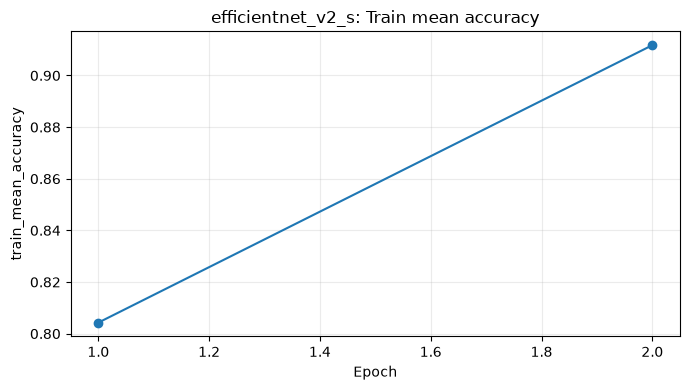

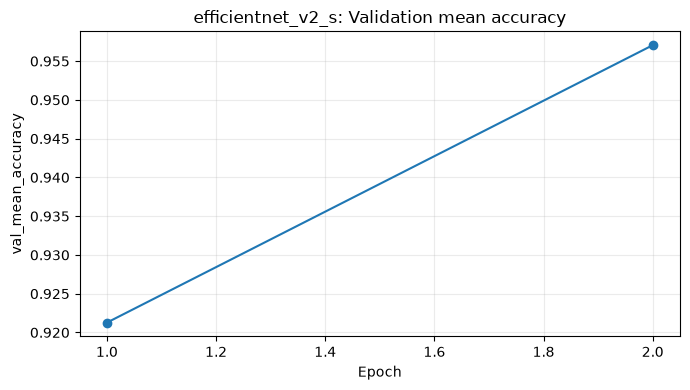

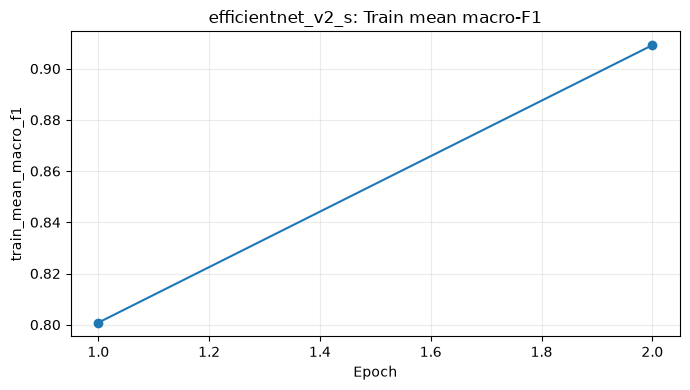

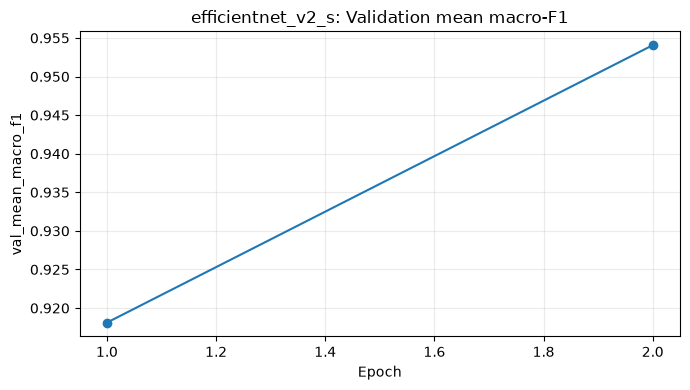

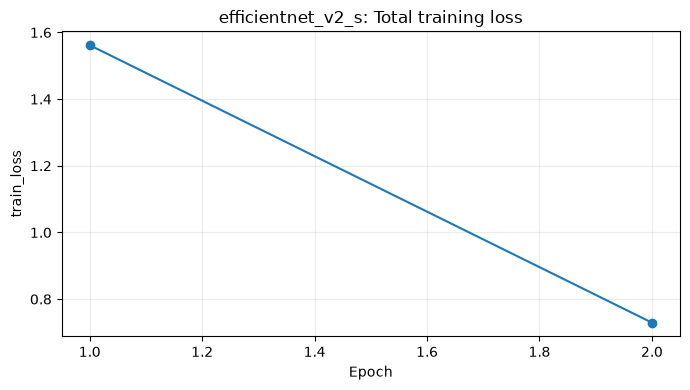

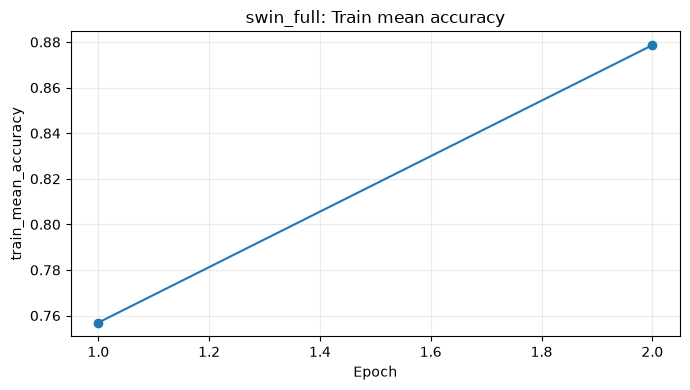

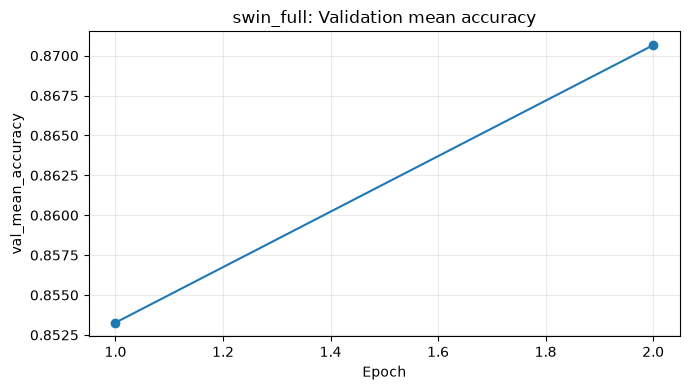

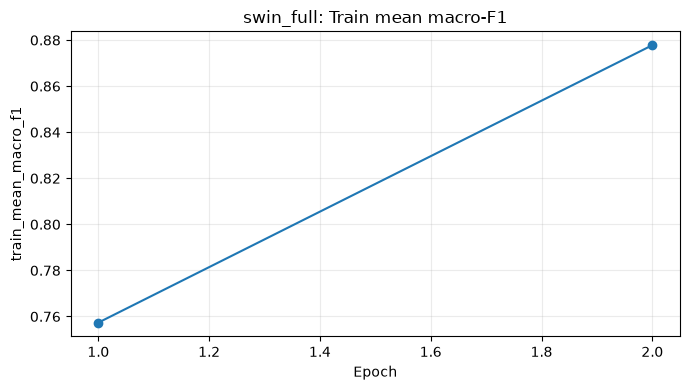

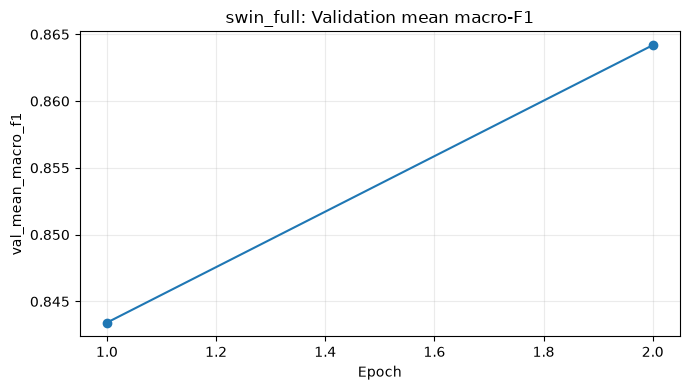

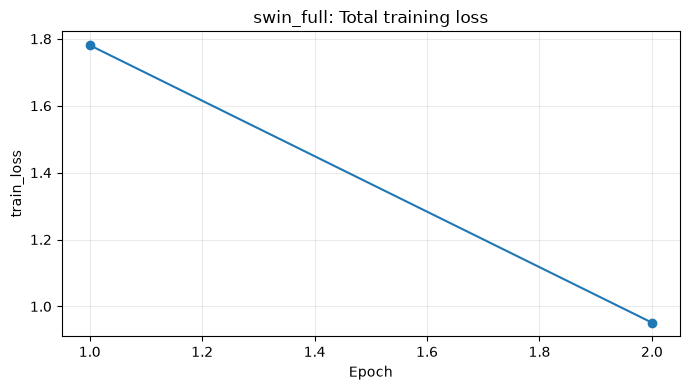

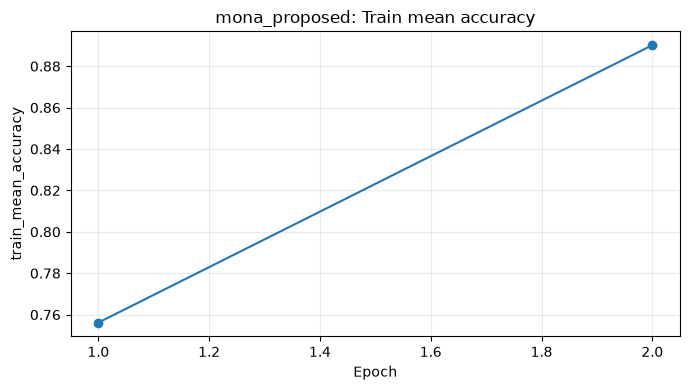

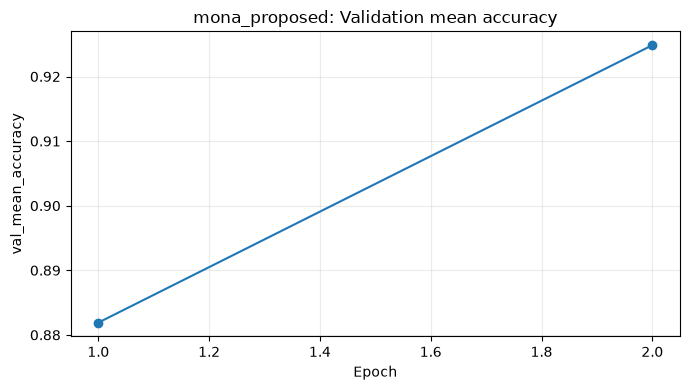

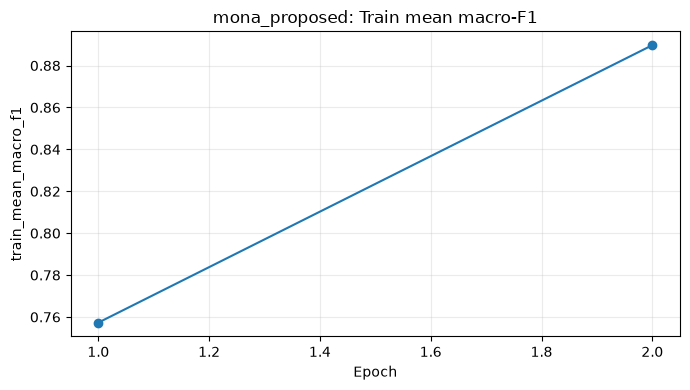

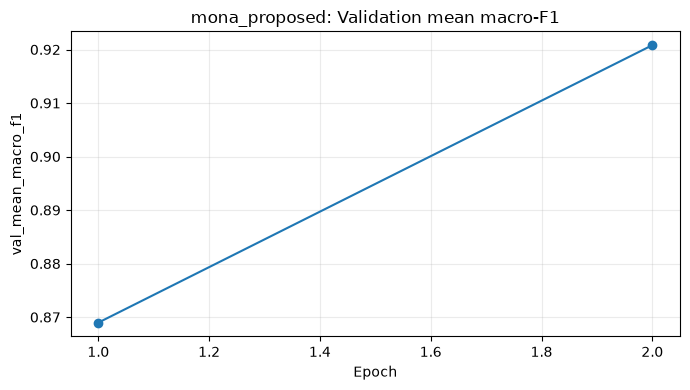

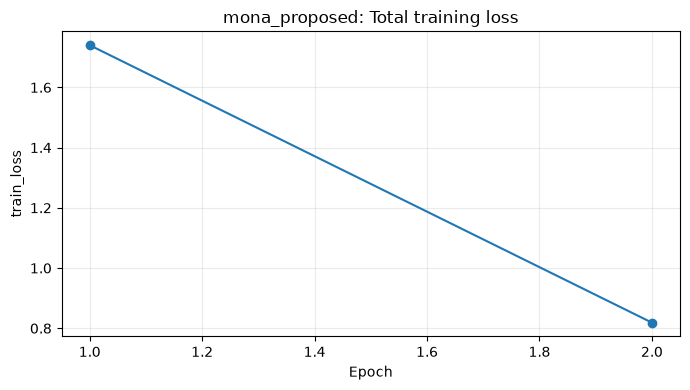

In [175]:
# 13.1 Plot training histories for the final three models.
def plot_history(history, model_name='model'):
    if history.empty:
        print(f'No history available for {model_name}.')
        return

    metrics = [
        ('train_mean_accuracy', 'Train mean accuracy', 'train_accuracy'),
        ('val_mean_accuracy', 'Validation mean accuracy', 'val_accuracy'),
        ('train_mean_macro_f1', 'Train mean macro-F1', 'train_macro_f1'),
        ('val_mean_macro_f1', 'Validation mean macro-F1', 'val_macro_f1'),
        ('train_loss', 'Total training loss', 'loss'),
    ]
    for metric, title, filename in metrics:
        if metric not in history:
            continue
        plt.figure(figsize=(7, 4))
        plt.plot(history['epoch'], history[metric], marker='o')
        plt.xlabel('Epoch')
        plt.ylabel(metric)
        plt.title(f'{model_name}: {title}')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f'{model_name}_{filename}.png', dpi=160)
        plt.show()

model_histories = {
    'efficientnet_v2_s': efficientnet_history,
    'swin_full': swin_full_history,
    'mona_proposed': proposed_history,
}
for model_name, history in model_histories.items():
    plot_history(history, model_name)


In [176]:
# 13.2 Calculate food, status, and colouring head metrics.
def head_metrics(probabilities, targets):
    results = {}
    label_sets = {
        'food': food_labels,
        'status': status_labels,
        'colour': colour_labels,
    }

    for head, labels in label_sets.items():
        y_true = targets[head]
        y_pred = probabilities[head].argmax(1)
        results[head] = {
            'accuracy': accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'weighted_f1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        }

        print(f'\n{head.upper()}')
        print(classification_report(
            y_true,
            y_pred,
            labels=range(len(labels)),
            target_names=labels,
            zero_division=0,
        ))

        matrix = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
        plt.figure(figsize=(max(6, len(labels) * 0.55), max(4, len(labels) * 0.45)))
        sns.heatmap(
            matrix,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=labels,
            yticklabels=labels,
        )
        plt.title(f'{head.capitalize()} confusion matrix')
        plt.xlabel('Predicted')
        plt.ylabel('True')
        plt.tight_layout()
        plt.show()

    return results


In [177]:
# 13.3 Calculate joint prediction and food-colouring compatibility metrics.
def joint_metrics(probabilities, targets):
    food_pred = probabilities['food'].argmax(1)
    status_pred = probabilities['status'].argmax(1)
    colour_pred = probabilities['colour'].argmax(1)

    food_correct = food_pred == targets['food']
    status_correct = status_pred == targets['status']
    colour_correct = colour_pred == targets['colour']
    joint_correct = food_correct & status_correct & colour_correct

    valid_pairs = {
        (food_to_id[food], colour_to_id[colour])
        for food, colours in train_food_colour_mapping.items()
        for colour in colours
    }
    incompatible = [
        (int(food), int(colour)) not in valid_pairs
        for food, colour in zip(food_pred, colour_pred)
    ]

    results = {
        'food_correct': float(food_correct.mean()),
        'food_status_correct': float((food_correct & status_correct).mean()),
        'joint_accuracy': float(joint_correct.mean()),
        'colour_accuracy_overall': float(colour_correct.mean()),
        'colour_accuracy_food_correct': float(colour_correct[food_correct].mean()),
        'food_incompatible_rate': float(np.mean(incompatible)),
    }

    display(pd.DataFrame([results]))
    return results, food_pred, status_pred, colour_pred, incompatible

In [178]:
# 13.4 Build the detailed prediction and error table.
def build_prediction_table(probabilities, targets, metadata):
    food_predictions = probabilities['food'].argmax(1)
    status_predictions = probabilities['status'].argmax(1)
    colour_predictions = probabilities['colour'].argmax(1)

    valid_pairs = {
        (food_to_id[food], colour_to_id[colour])
        for food, colours in train_food_colour_mapping.items()
        for colour in colours
    }

    invalid_food_colour = [
        (int(food), int(colour)) not in valid_pairs
        for food, colour in zip(food_predictions, colour_predictions)
    ]

    rows = []
    for index in range(len(metadata)):
        rows.append({
            'image_path': metadata.loc[index, 'path'],
            'true_food': food_labels[targets['food'][index]],
            'pred_food': food_labels[food_predictions[index]],
            'true_status': status_labels[targets['status'][index]],
            'pred_status': status_labels[status_predictions[index]],
            'true_colour': colour_labels[targets['colour'][index]],
            'pred_colour': colour_labels[colour_predictions[index]],
            'confidence': float(np.mean([
                probabilities[head][index].max()
                for head in ['food', 'status', 'colour']
            ])),
            'device': metadata.loc[index, 'device'],
            'light': metadata.loc[index, 'light'],
            'invalid_food_colour': invalid_food_colour[index],
        })

    return pd.DataFrame(rows)


FOOD
              precision    recall  f1-score   support

       Curry       1.00      1.00      1.00       126
  Dhal Curry       1.00      0.99      1.00       140
        Rice       1.00      1.00      1.00       386

    accuracy                           1.00       652
   macro avg       1.00      1.00      1.00       652
weighted avg       1.00      1.00      1.00       652



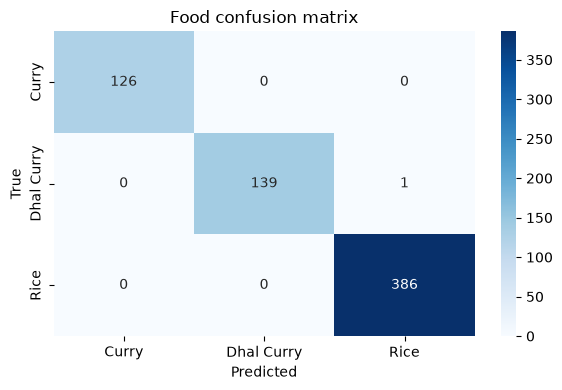


STATUS
              precision    recall  f1-score   support

  Artificial       0.98      0.89      0.93       357
     Natural       0.88      0.97      0.93       295

    accuracy                           0.93       652
   macro avg       0.93      0.93      0.93       652
weighted avg       0.93      0.93      0.93       652



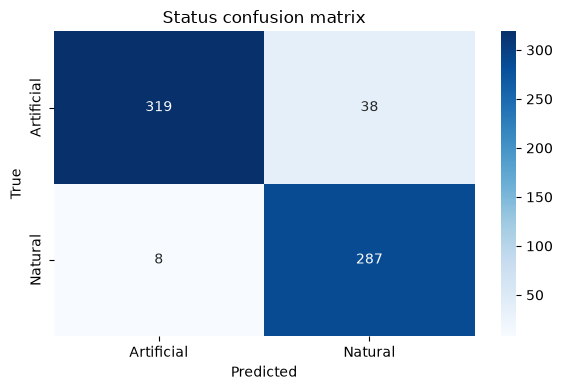


COLOUR
                precision    recall  f1-score   support

      Beetroot       1.00      1.00      1.00        33
        Carrot       0.80      0.59      0.68        34
  Chili Powder       0.80      1.00      0.89        33
 Christmas Red       1.00      0.17      0.29        42
    Egg Yellow       0.96      0.90      0.93        73
  Fuschia Pink       0.76      1.00      0.86        31
  Lemon Yellow       0.82      0.97      0.89        73
 Paprika Blend       1.00      0.58      0.73        33
Pillar Box Red       0.78      0.85      0.82        73
          Pure       0.69      0.96      0.81        56
     Rose Pink       1.00      0.88      0.94        33
 Sunset Orange       1.00      1.00      1.00        32
        Tomato       0.68      1.00      0.81        32
      Turmeric       0.98      0.86      0.92        74

      accuracy                           0.85       652
     macro avg       0.88      0.84      0.83       652
  weighted avg       0.87      0.85   

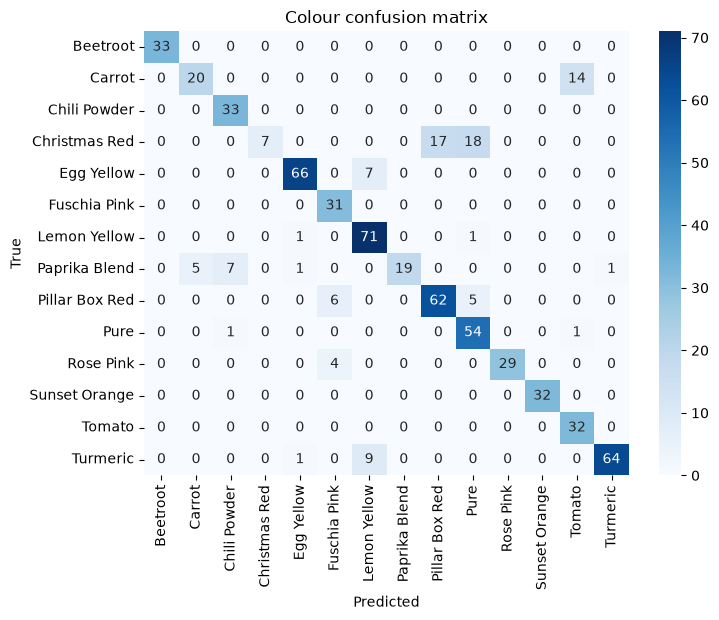

,food_correct,food_status_correct,joint_accuracy,colour_accuracy_overall,colour_accuracy_food_correct,food_incompatible_rate
0,0.998466,0.927914,0.825153,0.84816,0.849462,0.001534


{
  "food": {
    "accuracy": 0.9984662576687117,
    "macro_f1": 0.9983740365161723,
    "weighted_f1": 0.9984645010979065
  },
  "status": {
    "accuracy": 0.9294478527607362,
    "macro_f1": 0.9292774948122995,
    "weighted_f1": 0.9296075633373956
  },
  "colour": {
    "accuracy": 0.848159509202454,
    "macro_f1": 0.8251973908219179,
    "weighted_f1": 0.8321558697600545
  },
  "joint": {
    "food_correct": 0.9984662576687117,
    "food_status_correct": 0.9279141104294478,
    "joint_accuracy": 0.8251533742331288,
    "colour_accuracy_overall": 0.848159509202454,
    "colour_accuracy_food_correct": 0.8494623655913979,
    "food_incompatible_rate": 0.0015337423312883436
  }
}
Saved test predictions: c:\Destop\final research\research_outputs\predictions\mona_proposed_predictions.csv


In [179]:
# 13.5 Evaluate the proposed model and save its test predictions.
if proposed_model is not None:
    test_probabilities, test_targets, test_metadata = collect_predictions(proposed_model, test_loader)

    test_head_results = head_metrics(test_probabilities, test_targets)
    test_joint_results, _, _, _, _ = joint_metrics(test_probabilities, test_targets)
    test_results = {
        **test_head_results,
        'joint': test_joint_results,
    }

    test_metadata = test_metadata.reset_index(drop=True)
    error_table = build_prediction_table(
        test_probabilities,
        test_targets,
        test_metadata,
    )
    error_table.to_csv(OUTPUT_DIR / 'mona_proposed_predictions.csv', index=False)

    print(json.dumps(test_results, indent=2))
    print('Saved test predictions:', OUTPUT_DIR / 'mona_proposed_predictions.csv')
else:
    test_results = {}
    error_table = pd.DataFrame()
    test_probabilities = {}
    test_targets = {}
    print('No proposed model: set RUN_EXPERIMENTS=True.')

In [180]:
# 14.1 Slice metrics by device and lighting.
def slice_report(errors, group_column):
    rows = []

    for value, part in errors.groupby(group_column):
        food_score = f1_score(
            part['true_food'],
            part['pred_food'],
            labels=food_labels,
            average='macro',
            zero_division=0,
        )
        status_score = f1_score(
            part['true_status'],
            part['pred_status'],
            labels=status_labels,
            average='macro',
            zero_division=0,
        )
        colour_score = f1_score(
            part['true_colour'],
            part['pred_colour'],
            labels=colour_labels,
            average='macro',
            zero_division=0,
        )
        joint_correct = (
            (part['true_food'] == part['pred_food'])
            & (part['true_status'] == part['pred_status'])
            & (part['true_colour'] == part['pred_colour'])
        )

        rows.append({
            group_column: value,
            'food_macro_f1': food_score,
            'status_macro_f1': status_score,
            'colour_macro_f1': colour_score,
            'joint_accuracy': float(joint_correct.mean()),
        })

    result = pd.DataFrame(rows)
    display(result)
    result.to_csv(OUTPUT_DIR / f'{group_column}_metrics.csv', index=False)
    return result


if proposed_model is not None:
    device_results = slice_report(error_table, 'device')
    lighting_results = slice_report(error_table, 'light')

,device,food_macro_f1,status_macro_f1,colour_macro_f1,joint_accuracy
0,Apple,0.995098,0.892986,0.818610,0.813953
1,Samsung,1.000000,0.926102,0.861254,0.857798
2,Vivo,1.000000,0.967819,0.791447,0.803653


,light,food_macro_f1,status_macro_f1,colour_macro_f1,joint_accuracy
0,LED light,1.000000,0.924195,0.811699,0.821752
1,Yellow light,0.996718,0.934488,0.836771,0.828660


,,count
pred_food,pred_colour,
Dhal Curry,Tomato,1


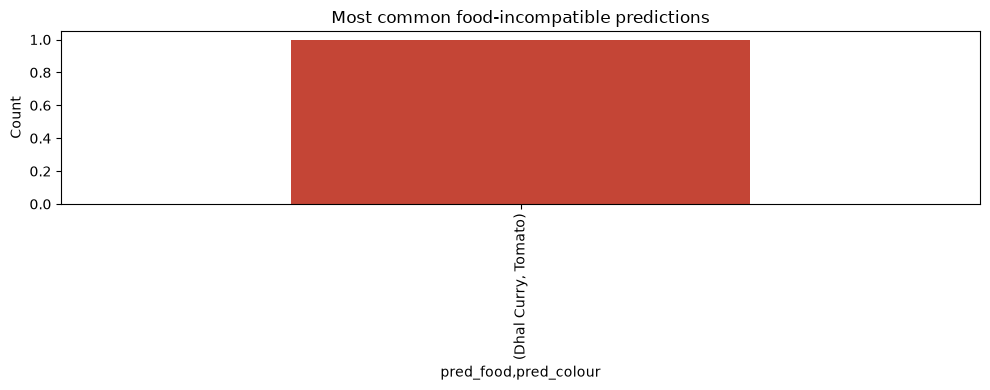

In [181]:
# 14.2 Inspect the most common food-colouring compatibility violations.
if proposed_model is not None:
    invalid_predictions = error_table[error_table['invalid_food_colour']]
    invalid_types = (
        invalid_predictions
        .groupby(['pred_food', 'pred_colour'])
        .size()
        .sort_values(ascending=False)
        .head(20)
    )

    display(invalid_types.to_frame('count'))
    invalid_types.to_csv(OUTPUT_DIR / 'invalid_prediction_types.csv')

    plt.figure(figsize=(10, 4))
    invalid_types.plot(kind='bar', color='#C44536')
    plt.ylabel('Count')
    plt.title('Most common food-incompatible predictions')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'invalid_prediction_types.png', dpi=150)
    plt.show()

Status positive class: Natural
ROC-AUC: 0.9852727531690643
Average precision: 0.9831913685610378


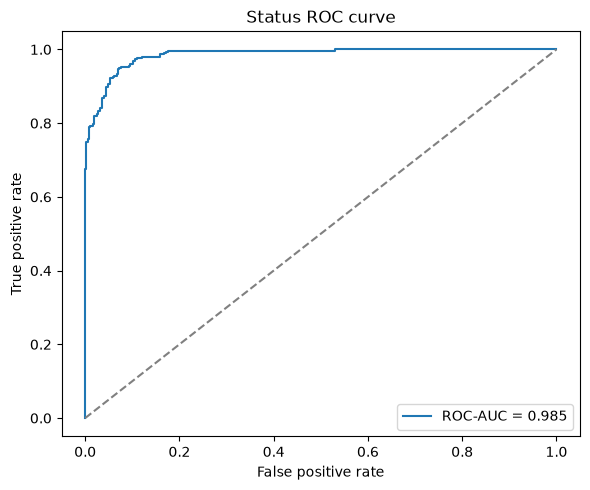

In [182]:
# 14.3 Analyse binary status ROC and average precision.
if proposed_model is not None and num_status == 2:
    positive_class = status_labels[1]
    status_targets = test_targets['status']
    status_scores = test_probabilities['status'][:, 1]

    roc_auc = roc_auc_score(status_targets, status_scores)
    average_precision = average_precision_score(status_targets, status_scores)
    print('Status positive class:', positive_class)
    print('ROC-AUC:', roc_auc)
    print('Average precision:', average_precision)

    false_positive_rate, true_positive_rate, _ = roc_curve(
        status_targets,
        status_scores,
    )
    plt.figure(figsize=(6, 5))
    plt.plot(false_positive_rate, true_positive_rate, label=f'ROC-AUC = {roc_auc:.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title('Status ROC curve')
    plt.legend()
    plt.tight_layout()
    plt.show()

In [183]:
# 14.4 Measure confidence calibration and inspect representative predictions.
def expected_calibration_error(probabilities, targets, bins=10):
    confidence = probabilities.max(1)
    predictions = probabilities.argmax(1)
    bin_edges = np.linspace(0, 1, bins + 1)
    calibration_error = 0.0

    for lower_edge, upper_edge in zip(bin_edges[:-1], bin_edges[1:]):
        in_bin = (confidence > lower_edge) & (confidence <= upper_edge)
        if in_bin.any():
            mean_confidence = confidence[in_bin].mean()
            mean_accuracy = (predictions[in_bin] == targets[in_bin]).mean()
            calibration_error += in_bin.mean() * abs(mean_confidence - mean_accuracy)

    return float(calibration_error)


if proposed_model is not None:
    calibration_scores = {
        head: expected_calibration_error(
            test_probabilities[head],
            test_targets[head],
        )
        for head in ['food', 'status', 'colour']
    }
    print('ECE food/status/colour:', calibration_scores)

    print('Highest-confidence predictions:')
    display(error_table.sort_values('confidence', ascending=False).head(10))

    print('Lowest-confidence predictions:')
    display(error_table.sort_values('confidence').head(10))

    print('Food-colouring compatibility errors:')
    display(error_table[error_table['invalid_food_colour']].head(10))

ECE food/status/colour: {'food': 0.0009447076569306105, 'status': 0.03166956038562797, 'colour': 0.029455757122829686}
Highest-confidence predictions:


,image_path,true_food,pred_food,true_status,pred_status,true_colour,pred_colour,confidence,device,light,invalid_food_colour
474,c:\Destop\final research\Dataset\NSSa90.jpg,Rice,Rice,Natural,Natural,Chili Powder,Chili Powder,0.999799,Samsung,Yellow light,False
614,c:\Destop\final research\Dataset\CNIPu36.jpg,Curry,Curry,Natural,Natural,Pure,Pure,0.999777,Apple,LED light,False
569,c:\Destop\final research\Dataset\NIPa44.jpg,Rice,Rice,Natural,Natural,Chili Powder,Chili Powder,0.999769,Apple,Yellow light,False
4,c:\Destop\final research\Dataset\NSPo90.jpg,Rice,Rice,Natural,Natural,Chili Powder,Chili Powder,0.999760,Samsung,Yellow light,False
580,c:\Destop\final research\Dataset\CNVPu4.jpg,Curry,Curry,Natural,Natural,Pure,Pure,0.999755,Vivo,LED light,False
415,c:\Destop\final research\Dataset\CNIPu88.jpg,Curry,Curry,Natural,Natural,Pure,Pure,0.999710,Apple,Yellow light,False
71,c:\Destop\final research\Dataset\CNVPu72.jpg,Curry,Curry,Natural,Natural,Pure,Pure,0.999710,Vivo,Yellow light,False
423,c:\Destop\final research\Dataset\CNIPu39.jpg,Curry,Curry,Natural,Natural,Pure,Pure,0.999696,Apple,LED light,False
511,c:\Destop\final research\Dataset\CNVPu37.jpg,Curry,Curry,Natural,Natural,Pure,Pure,0.999693,Vivo,LED light,False
498,c:\Destop\final research\Dataset\NIPa90.jpg,Rice,Rice,Natural,Natural,Chili Powder,Chili Powder,0.999691,Apple,Yellow light,False


Lowest-confidence predictions:


,image_path,true_food,pred_food,true_status,pred_status,true_colour,pred_colour,confidence,device,light,invalid_food_colour
54,c:\Destop\final research\Dataset\DNSPu17.jpg,Dhal Curry,Dhal Curry,Natural,Artificial,Pure,Pure,0.653877,Samsung,Yellow light,False
367,c:\Destop\final research\Dataset\AISa102.jpg,Rice,Rice,Artificial,Artificial,Egg Yellow,Egg Yellow,0.671361,Apple,LED light,False
64,c:\Destop\final research\Dataset\CAVCh61.jpg,Curry,Curry,Artificial,Artificial,Christmas Red,Pillar Box Red,0.681531,Vivo,Yellow light,False
200,c:\Destop\final research\Dataset\CAVCh72.jpg,Curry,Curry,Artificial,Artificial,Christmas Red,Christmas Red,0.691004,Vivo,LED light,False
107,c:\Destop\final research\Dataset\DNVTu24.jpg,Dhal Curry,Dhal Curry,Natural,Natural,Turmeric,Egg Yellow,0.695876,Vivo,Yellow light,False
169,c:\Destop\final research\Dataset\DNVTu69.jpg,Dhal Curry,Dhal Curry,Natural,Natural,Turmeric,Lemon Yellow,0.700602,Vivo,LED light,False
383,c:\Destop\final research\Dataset\DNVTu96.jpg,Dhal Curry,Dhal Curry,Natural,Natural,Turmeric,Turmeric,0.702583,Vivo,Yellow light,False
55,c:\Destop\final research\Dataset\DNVTu45.jpg,Dhal Curry,Dhal Curry,Natural,Natural,Turmeric,Lemon Yellow,0.716230,Vivo,LED light,False
255,c:\Destop\final research\Dataset\CAVCh73.jpg,Curry,Curry,Artificial,Artificial,Christmas Red,Pillar Box Red,0.720587,Vivo,LED light,False
344,c:\Destop\final research\Dataset\CASCh18.jpg,Curry,Curry,Artificial,Artificial,Christmas Red,Pillar Box Red,0.726103,Samsung,Yellow light,False


Food-colouring compatibility errors:


,image_path,true_food,pred_food,true_status,pred_status,true_colour,pred_colour,confidence,device,light,invalid_food_colour
637,c:\Destop\final research\Dataset\DNVPu18.jpg,Dhal Curry,Dhal Curry,Natural,Natural,Pure,Tomato,0.945636,Vivo,Yellow light,True


# 14. Baselines, Ablations, Efficiency, and Cross-Device Generalisation

Run the controlled model list on the identical standard split. The same training loop, loss, early stopping, and evaluation are used. Optional models are disabled by default because pretrained downloads and GPU memory vary. Unseen-device training uses all discovered devices except the held-out device and tests only on that device. Leave-one-device-out is available by setting `RUN_LODO=True` and is intentionally not run automatically.

In [184]:
# 15.1 Evaluate the final three-model comparison without retraining.
model_objects = {
    'efficientnet_v2_s': (efficientnet_model, efficientnet_history, efficientnet_info),
    'swin_full': (swin_full_model, swin_full_history, swin_full_info),
    'mona_proposed': (proposed_model, proposed_history, proposed_info),
}
comparison_rows = []
trained_models = {}

for model_name in FINAL_MODEL_NAMES:
    model, history, info = model_objects[model_name]
    if model is None:
        print(f'Skipping {model_name}: model was not trained or loaded.')
        continue

    test_probabilities, test_targets, test_metadata = collect_predictions(model, test_loader)
    test_metrics = metrics_from_predictions(test_probabilities, test_targets, 'test_')
    prediction_table = build_prediction_table(
        test_probabilities,
        test_targets,
        test_metadata.reset_index(drop=True),
    )
    prediction_table.to_csv(OUTPUT_DIR / f'{model_name}_predictions.csv', index=False)

    best_epoch = int(info.get('best_epoch', 1))
    history_row = history.loc[history['epoch'] == best_epoch].iloc[0] if not history.empty else pd.Series(dtype=float)
    row = {
        'model': model_name,
        'best_epoch': best_epoch,
        'trainable_parameters': info.get('trainable_parameters'),
        'trainable_percent': info.get('trainable_percent'),
        'training_seconds': info.get('training_seconds'),
        'reused_checkpoint': info.get('reused_checkpoint', False),
    }
    for head in ['food', 'status', 'colour']:
        for metric in ['accuracy', 'macro_f1', 'weighted_f1', 'mse', 'rmse']:
            row[f'train_{head}_{metric}'] = history_row.get(f'train_{head}_{metric}', np.nan)
            row[f'val_{head}_{metric}'] = history_row.get(f'val_{head}_{metric}', np.nan)
            row[f'test_{head}_{metric}'] = test_metrics[f'test_{head}_{metric}']
    row['train_mean_accuracy'] = history_row.get('train_mean_accuracy', np.nan)
    row['val_mean_accuracy'] = history_row.get('val_mean_accuracy', np.nan)
    row['test_mean_accuracy'] = test_metrics['test_mean_accuracy']
    row['train_mean_macro_f1'] = history_row.get('train_mean_macro_f1', np.nan)
    row['val_mean_macro_f1'] = history_row.get('val_mean_macro_f1', np.nan)
    row['test_mean_macro_f1'] = test_metrics['test_mean_macro_f1']
    row['test_joint_accuracy'] = test_metrics['test_joint_accuracy']
    row['test_food_colour_incompatible_rate'] = test_metrics['test_food_colour_incompatible_rate']
    comparison_rows.append(row)
    trained_models[model_name] = {
        'model': model,
        'history': history,
        'info': info,
        'test_metrics': test_metrics,
    }

comparison_table = pd.DataFrame(comparison_rows)
if not comparison_table.empty:
    display(comparison_table[['model', 'train_mean_accuracy', 'val_mean_accuracy', 'test_mean_accuracy',
                              'train_mean_macro_f1', 'val_mean_macro_f1', 'test_mean_macro_f1',
                              'test_joint_accuracy', 'test_food_colour_incompatible_rate',
                              'test_food_accuracy', 'test_status_accuracy', 'test_colour_accuracy',
                              'reused_checkpoint']])
else:
    print('No final comparison results are available.')

,model,train_mean_accuracy,val_mean_accuracy,test_mean_accuracy,train_mean_macro_f1,val_mean_macro_f1,test_mean_macro_f1,test_joint_accuracy,test_food_colour_incompatible_rate,test_food_accuracy,test_status_accuracy,test_colour_accuracy,reused_checkpoint
0,efficientnet_v2_s,0.911732,0.957055,0.956544,0.909163,0.954061,0.953594,0.877301,0.000000,1.000000,0.992331,0.877301,False
1,swin_full,0.878618,0.870654,0.887014,0.877785,0.864184,0.880187,0.737730,0.000000,0.998466,0.914110,0.748466,False
2,mona_proposed,0.890132,0.924847,0.925358,0.889723,0.920805,0.917616,0.825153,0.001534,0.998466,0.929448,0.848160,False


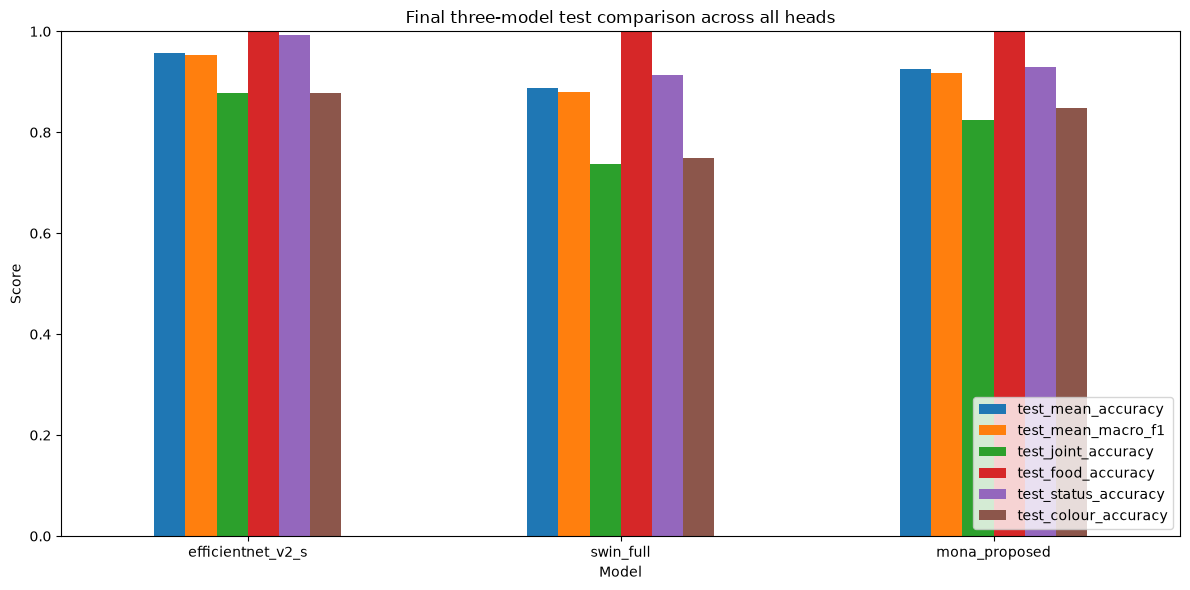

Highest test mean macro-F1: efficientnet_v2_s
This comparison supports an empirical result; it does not guarantee that Mona is best before testing.


In [185]:
# 15.2 Save and plot the complete final comparison.
if not comparison_table.empty:
    comparison_table.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)

    comparison_metrics = comparison_table.set_index('model')[[
        'test_mean_accuracy',
        'test_mean_macro_f1',
        'test_joint_accuracy',
        'test_food_accuracy',
        'test_status_accuracy',
        'test_colour_accuracy',
    ]]
    comparison_metrics.plot(kind='bar', figsize=(12, 6))
    plt.ylim(0, 1)
    plt.title('Final three-model test comparison across all heads')
    plt.ylabel('Score')
    plt.xlabel('Model')
    plt.xticks(rotation=0)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=160)
    plt.show()

    best_model = comparison_table.loc[comparison_table['test_mean_macro_f1'].idxmax(), 'model']
    print('Highest test mean macro-F1:', best_model)
    print('This comparison supports an empirical result; it does not guarantee that Mona is best before testing.')


In [186]:
# 15.3 Save trained model checkpoints for later inference.
saved_model_paths = {}

for model_name, details in trained_models.items():
    trained_model = details['model']
    model_info = details['info']
    checkpoint_path = OUTPUT_DIR / f'{model_name}_final.pt'

    torch.save({
        'model_name': model_name,
        'model_state_dict': trained_model.state_dict(),
        'food_labels': food_labels,
        'status_labels': status_labels,
        'colour_labels': colour_labels,
        'food_to_id': food_to_id,
        'status_to_id': status_to_id,
        'colour_to_id': colour_to_id,
        'parameters': parameter_report(trained_model),
        'training_info': model_info,
    }, checkpoint_path)
    saved_model_paths[model_name] = checkpoint_path

if saved_model_paths:
    print('Saved model checkpoints:')
    for model_name, checkpoint_path in saved_model_paths.items():
        print(model_name, '->', checkpoint_path)
else:
    print('No trained models to save. Set RUN_EXPERIMENTS=True first.')

Saved model checkpoints:
efficientnet_v2_s -> c:\Destop\final research\research_outputs\models\efficientnet_v2_s_final.pt
swin_full -> c:\Destop\final research\research_outputs\models\swin_full_final.pt
mona_proposed -> c:\Destop\final research\research_outputs\models\mona_proposed_final.pt


Best standard-test model: efficientnet_v2_s
Loaded checkpoint: c:\Destop\final research\research_outputs\models\efficientnet_v2_s_final.pt
Image: c:\Destop\final research\Dataset\NSPo130.jpg
Device: Samsung | Light: Yellow light


,factor,original_label,predicted_label,confidence
0,Food type,Rice,Rice,0.999924
1,Natural/artificial status,Natural,Natural,0.999960
2,Colouring identity,Carrot,Carrot,0.921169


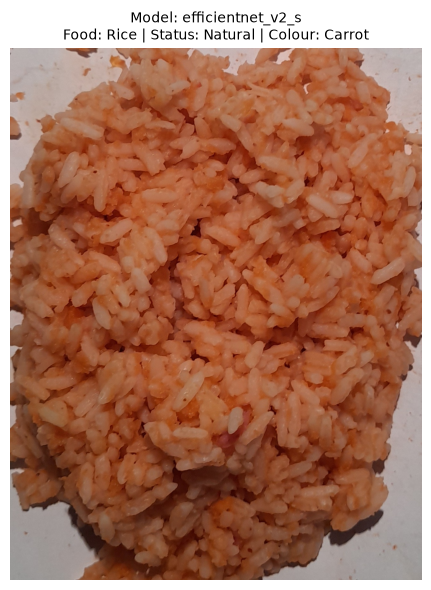

In [187]:
# 15.4 Predict one image with the best standard-test model.
if saved_model_paths and len(test_df) > 0 and not comparison_table.empty:
    best_standard_model = comparison_table.loc[
        comparison_table['test_mean_macro_f1'].idxmax(), 'model'
    ]
    checkpoint_path = saved_model_paths[best_standard_model]
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    loaded_model = build_model(best_standard_model)
    loaded_model.load_state_dict(checkpoint['model_state_dict'])
    loaded_model.eval()

    sample_row = test_df.iloc[0]
    original_image = Image.open(sample_row['image_path']).convert('RGB')
    model_input = eval_transform(original_image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        prediction_outputs = loaded_model(model_input)

    prediction_probabilities = {
        head: torch.softmax(prediction_outputs[head], dim=1).cpu().numpy()[0]
        for head in ['food', 'status', 'colour']
    }
    predicted_ids = {
        head: int(prediction_probabilities[head].argmax())
        for head in prediction_probabilities
    }
    predicted_labels = {
        'food': food_labels[predicted_ids['food']],
        'status': status_labels[predicted_ids['status']],
        'colour': colour_labels[predicted_ids['colour']],
    }
    prediction_confidence = {
        head: float(prediction_probabilities[head][predicted_ids[head]])
        for head in prediction_probabilities
    }

    prediction_details = pd.DataFrame([
        {
            'factor': 'Food type',
            'original_label': sample_row[FOOD_COLUMN],
            'predicted_label': predicted_labels['food'],
            'confidence': prediction_confidence['food'],
        },
        {
            'factor': 'Natural/artificial status',
            'original_label': sample_row[STATUS_COLUMN],
            'predicted_label': predicted_labels['status'],
            'confidence': prediction_confidence['status'],
        },
        {
            'factor': 'Colouring identity',
            'original_label': sample_row[COLOUR_COLUMN],
            'predicted_label': predicted_labels['colour'],
            'confidence': prediction_confidence['colour'],
        },
    ])

    print('Best standard-test model:', best_standard_model)
    print('Loaded checkpoint:', checkpoint_path)
    print('Image:', sample_row['image_path'])
    print('Device:', sample_row[PHONE_COLUMN], '| Light:', sample_row[LIGHT_COLUMN])
    display(prediction_details)

    figure, axis = plt.subplots(figsize=(7, 6))
    axis.imshow(original_image)
    axis.axis('off')
    axis.set_title(
        f"Model: {best_standard_model}\n"
        f"Food: {predicted_labels['food']} | "
        f"Status: {predicted_labels['status']} | "
        f"Colour: {predicted_labels['colour']}",
        fontsize=10,
    )
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'best_model_single_image_prediction.png', dpi=160)
    plt.show()
else:
    print('Best-model inference is unavailable until the standard comparison finishes.')


In [188]:
# 15.5 Prepare loaders for the strict unseen-device experiment.
unseen_train_loader = DataLoader(
    FoodDataset(unseen_train_df, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
unseen_val_loader = DataLoader(
    FoodDataset(unseen_val_df, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
unseen_test_loader = DataLoader(
    FoodDataset(unseen_test_df, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

unseen_models = {}
unseen_comparison_rows = []

print('Held-out device:', unseen_device)
print('Unseen train:', len(unseen_train_df))
print('Unseen validation:', len(unseen_val_df))
print('Unseen test:', len(unseen_test_df))

Held-out device: Vivo
Unseen train: 2093
Unseen validation: 370
Unseen test: 219


In [189]:
# 15.6 Train the EfficientNetV2-S model on the unseen-device split.
unseen_efficientnet_model = None
unseen_efficientnet_history = pd.DataFrame()
unseen_efficientnet_info = {}

if RUN_EXPERIMENTS and 'efficientnet_v2_s' in FINAL_MODEL_NAMES:
    unseen_efficientnet_model = build_model('efficientnet_v2_s')
    unseen_efficientnet_model, unseen_efficientnet_history, unseen_efficientnet_info = train_model(
        unseen_efficientnet_model,
        'efficientnet_v2_s_unseen_device',
        unseen_train_loader,
        unseen_val_loader,
    )
else:
    print('Unseen EfficientNetV2-S training is disabled.')

C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
efficientnet_v2_s_unseen_device epoch 1/2:   0%|          | 0/131 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 1: loss=1.7461, train-F1=0.7817, val-F1=0.9327, val-accuracy=0.9333


efficientnet_v2_s_unseen_device epoch 2/2:   0%|          | 0/131 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 2: loss=0.8488, train-F1=0.8923, val-F1=0.9490, val-accuracy=0.9486


In [190]:
# 15.7 Train the full Swin-T model on the unseen-device split.
unseen_swin_model = None
unseen_swin_history = pd.DataFrame()
unseen_swin_info = {}

if RUN_EXPERIMENTS and 'swin_full' in FINAL_MODEL_NAMES:
    unseen_swin_model = build_model('swin_full')
    unseen_swin_model, unseen_swin_history, unseen_swin_info = train_model(
        unseen_swin_model,
        'swin_full_unseen_device',
        unseen_train_loader,
        unseen_val_loader,
    )
else:
    print('Unseen Swin-T training is disabled.')

C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
swin_full_unseen_device epoch 1/2:   0%|          | 0/131 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 1: loss=1.8410, train-F1=0.7548, val-F1=0.8515, val-accuracy=0.8613


swin_full_unseen_device epoch 2/2:   0%|          | 0/131 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 2: loss=1.0298, train-F1=0.8624, val-F1=0.9192, val-accuracy=0.9225


In [191]:
# 15.8 Train the proposed Mona model on the unseen-device split.
unseen_mona_model = None
unseen_mona_history = pd.DataFrame()
unseen_mona_info = {}

if RUN_EXPERIMENTS and 'mona_proposed' in FINAL_MODEL_NAMES and MONA_AVAILABLE:
    unseen_mona_model = build_model('mona_proposed')
    unseen_mona_model, unseen_mona_history, unseen_mona_info = train_model(
        unseen_mona_model,
        'mona_proposed_unseen_device',
        unseen_train_loader,
        unseen_val_loader,
    )
else:
    print('Unseen Mona training is disabled.')

C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
mona_proposed_unseen_device epoch 1/2:   0%|          | 0/131 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 1: loss=1.9486, train-F1=0.7299, val-F1=0.8058, val-accuracy=0.8216


mona_proposed_unseen_device epoch 2/2:   0%|          | 0/131 [00:00<?, ?it/s]C:\Users\S.LINGAJAN\AppData\Local\Temp\ipykernel_15328\3655470015.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch 2: loss=0.9594, train-F1=0.8687, val-F1=0.9281, val-accuracy=0.9297


In [192]:
# 15.9 Evaluate all unseen-device models on the held-out test images.
unseen_model_runs = {
    'efficientnet_v2_s': (
        unseen_efficientnet_model,
        unseen_efficientnet_history,
        unseen_efficientnet_info,
    ),
    'swin_full': (
        unseen_swin_model,
        unseen_swin_history,
        unseen_swin_info,
    ),
    'mona_proposed': (
        unseen_mona_model,
        unseen_mona_history,
        unseen_mona_info,
    ),
}

unseen_models = {}
unseen_comparison_rows = []

for model_name in FINAL_MODEL_NAMES:
    model, history, info = unseen_model_runs[model_name]
    if model is None:
        print(f'Skipping unseen {model_name}: model was not trained.')
        continue

    probabilities, targets, metadata = collect_predictions(
        model,
        unseen_test_loader,
    )
    metrics = metrics_from_predictions(probabilities, targets, 'test_')
    errors = build_prediction_table(
        probabilities,
        targets,
        metadata.reset_index(drop=True),
    )
    errors.to_csv(
        OUTPUT_DIR / f'{model_name}_unseen_device_predictions.csv',
        index=False,
    )

    unseen_models[model_name] = {
        'model': model,
        'history': history,
        'info': info,
        'metrics': metrics,
    }
    unseen_comparison_rows.append({
        'model': model_name,
        'held_out_device': unseen_device,
        'test_mean_accuracy': metrics['test_mean_accuracy'],
        'test_mean_macro_f1': metrics['test_mean_macro_f1'],
        'test_joint_accuracy': metrics['test_joint_accuracy'],
        'test_food_accuracy': metrics['test_food_accuracy'],
        'test_status_accuracy': metrics['test_status_accuracy'],
        'test_colour_accuracy': metrics['test_colour_accuracy'],
        'test_food_mse': metrics['test_food_mse'],
        'test_status_mse': metrics['test_status_mse'],
        'test_colour_mse': metrics['test_colour_mse'],
        'test_food_colour_incompatible_rate': metrics[
            'test_food_colour_incompatible_rate'
        ],
        'trainable_parameters': info.get('trainable_parameters'),
        'trainable_percent': info.get('trainable_percent'),
        'reused_checkpoint': info.get('reused_checkpoint', False),
    })

unseen_comparison_table = pd.DataFrame(unseen_comparison_rows)
if not unseen_comparison_table.empty:
    unseen_comparison_table.to_csv(
        OUTPUT_DIR / 'unseen_device_model_comparison.csv',
        index=False,
    )
    display(unseen_comparison_table)
else:
    print('No unseen-device results are available.')

,model,held_out_device,test_mean_accuracy,test_mean_macro_f1,test_joint_accuracy,test_food_accuracy,test_status_accuracy,test_colour_accuracy,test_food_mse,test_status_mse,test_colour_mse,test_food_colour_incompatible_rate,trainable_parameters,trainable_percent,reused_checkpoint
0,efficientnet_v2_s,Vivo,0.861492,0.849290,0.689498,0.995434,0.885845,0.703196,0.003542,0.085433,0.030701,0.000000,21014639,100.000000,False
1,swin_full,Vivo,0.722983,0.690535,0.442922,0.981735,0.721461,0.465753,0.009075,0.203132,0.054481,0.000000,27825049,100.000000,False
2,mona_proposed,Vivo,0.805175,0.785581,0.543379,0.958904,0.881279,0.575342,0.017999,0.092465,0.043931,0.004566,1713823,5.862596,False


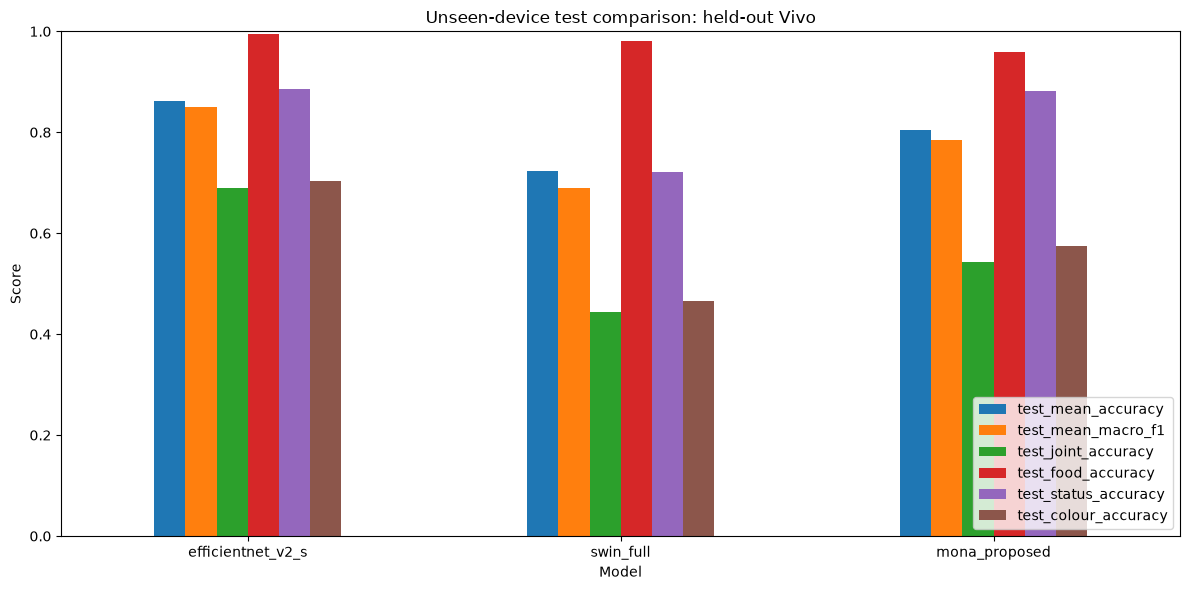

Best unseen-device model: efficientnet_v2_s


In [193]:
# 15.10 Plot the unseen-device comparison.
if not unseen_comparison_table.empty:
    unseen_metrics_plot = unseen_comparison_table.set_index('model')[[
        'test_mean_accuracy',
        'test_mean_macro_f1',
        'test_joint_accuracy',
        'test_food_accuracy',
        'test_status_accuracy',
        'test_colour_accuracy',
    ]]
    unseen_metrics_plot.plot(kind='bar', figsize=(12, 6))
    plt.ylim(0, 1)
    plt.title(f'Unseen-device test comparison: held-out {unseen_device}')
    plt.ylabel('Score')
    plt.xlabel('Model')
    plt.xticks(rotation=0)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'unseen_device_model_comparison.png', dpi=160)
    plt.show()

    best_unseen_model = unseen_comparison_table.loc[
        unseen_comparison_table['test_mean_macro_f1'].idxmax(), 'model'
    ]
    print('Best unseen-device model:', best_unseen_model)
else:
    best_unseen_model = None
    print('No unseen-device plot is available.')

In [194]:
# 15.11 Save all unseen-device checkpoints.
if unseen_models:
    unseen_saved_model_paths = {}
    for model_name, details in unseen_models.items():
        unseen_checkpoint_path = OUTPUT_DIR / f'{model_name}_unseen_device_final.pt'
        torch.save({
            'model_name': f'{model_name}_unseen_device',
            'model_state_dict': details['model'].state_dict(),
            'food_labels': food_labels,
            'status_labels': status_labels,
            'colour_labels': colour_labels,
            'food_to_id': food_to_id,
            'status_to_id': status_to_id,
            'colour_to_id': colour_to_id,
            'parameters': parameter_report(details['model']),
            'training_info': details['info'],
            'held_out_device': unseen_device,
        }, unseen_checkpoint_path)
        unseen_saved_model_paths[model_name] = unseen_checkpoint_path
        print(model_name, '->', unseen_checkpoint_path)
else:
    unseen_saved_model_paths = {}
    print('No unseen-device models were trained.')

efficientnet_v2_s -> c:\Destop\final research\research_outputs\models\efficientnet_v2_s_unseen_device_final.pt
swin_full -> c:\Destop\final research\research_outputs\models\swin_full_unseen_device_final.pt
mona_proposed -> c:\Destop\final research\research_outputs\models\mona_proposed_unseen_device_final.pt


In [195]:
# 15.12 Compare standard and unseen-device performance for every model.
if not comparison_table.empty and not unseen_comparison_table.empty:
    standard_metrics = comparison_table.set_index('model')
    unseen_metrics = unseen_comparison_table.set_index('model')
    performance_rows = []

    for model_name in FINAL_MODEL_NAMES:
        if model_name not in unseen_metrics.index:
            continue
        performance_rows.append({
            'model': model_name,
            'standard_test_mean_macro_f1': standard_metrics.loc[
                model_name, 'test_mean_macro_f1'
            ],
            'unseen_test_mean_macro_f1': unseen_metrics.loc[
                model_name, 'test_mean_macro_f1'
            ],
            'macro_f1_drop': standard_metrics.loc[
                model_name, 'test_mean_macro_f1'
            ] - unseen_metrics.loc[model_name, 'test_mean_macro_f1'],
            'standard_test_joint_accuracy': standard_metrics.loc[
                model_name, 'test_joint_accuracy'
            ],
            'unseen_test_joint_accuracy': unseen_metrics.loc[
                model_name, 'test_joint_accuracy'
            ],
            'joint_accuracy_drop': standard_metrics.loc[
                model_name, 'test_joint_accuracy'
            ] - unseen_metrics.loc[model_name, 'test_joint_accuracy'],
        })

    performance_drop_table = pd.DataFrame(performance_rows)
    performance_drop_table.to_csv(
        OUTPUT_DIR / 'standard_vs_unseen_device_comparison.csv',
        index=False,
    )
    display(performance_drop_table)
else:
    performance_drop_table = pd.DataFrame()
    print('Standard and unseen comparison tables are not both available.')

,model,standard_test_mean_macro_f1,unseen_test_mean_macro_f1,macro_f1_drop,standard_test_joint_accuracy,unseen_test_joint_accuracy,joint_accuracy_drop
0,efficientnet_v2_s,0.953594,0.849290,0.104304,0.877301,0.689498,0.187803
1,swin_full,0.880187,0.690535,0.189653,0.737730,0.442922,0.294808
2,mona_proposed,0.917616,0.785581,0.132035,0.825153,0.543379,0.281774


# 15. Explainability, Error Analysis, Statistical Analysis, Findings, Limitations, and Conclusion

Transformer explanations must match the architecture. The notebook therefore uses attention rollout only when the trained Swin exposes attention tensors; otherwise it reports the unsupported hook explicitly instead of applying CNN Grad-CAM incorrectly. Error analysis is generated from saved prediction rows, including representative incorrect images and high-confidence mistakes. Repeated-seed significance tests are only valid when multiple independent runs are enabled.

Incorrect multi-head rows: 114 / 652


,image_path,true_food,pred_food,true_status,pred_status,true_colour,pred_colour,confidence,device,light,invalid_food_colour
460,c:\Destop\final research\Dataset\CAICh7.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.994258,Apple,LED light,False
640,c:\Destop\final research\Dataset\CAICh25.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.994208,Apple,Yellow light,False
560,c:\Destop\final research\Dataset\CAICh6.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.993265,Apple,LED light,False
626,c:\Destop\final research\Dataset\CAICh8.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.991245,Apple,LED light,False
468,c:\Destop\final research\Dataset\NISa21.jpg,Rice,Rice,Natural,Natural,Paprika Blend,Chili Powder,0.991025,Apple,LED light,False
382,c:\Destop\final research\Dataset\CAICh14.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.988685,Apple,LED light,False
167,c:\Destop\final research\Dataset\CASCh44.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.988434,Samsung,LED light,False
512,c:\Destop\final research\Dataset\CAICh42.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.987822,Apple,LED light,False
11,c:\Destop\final research\Dataset\AVPa133.jpg,Rice,Rice,Artificial,Artificial,Rose Pink,Fuschia Pink,0.984951,Vivo,Yellow light,False
467,c:\Destop\final research\Dataset\CAICh24.jpg,Curry,Curry,Artificial,Natural,Christmas Red,Pure,0.984861,Apple,Yellow light,False


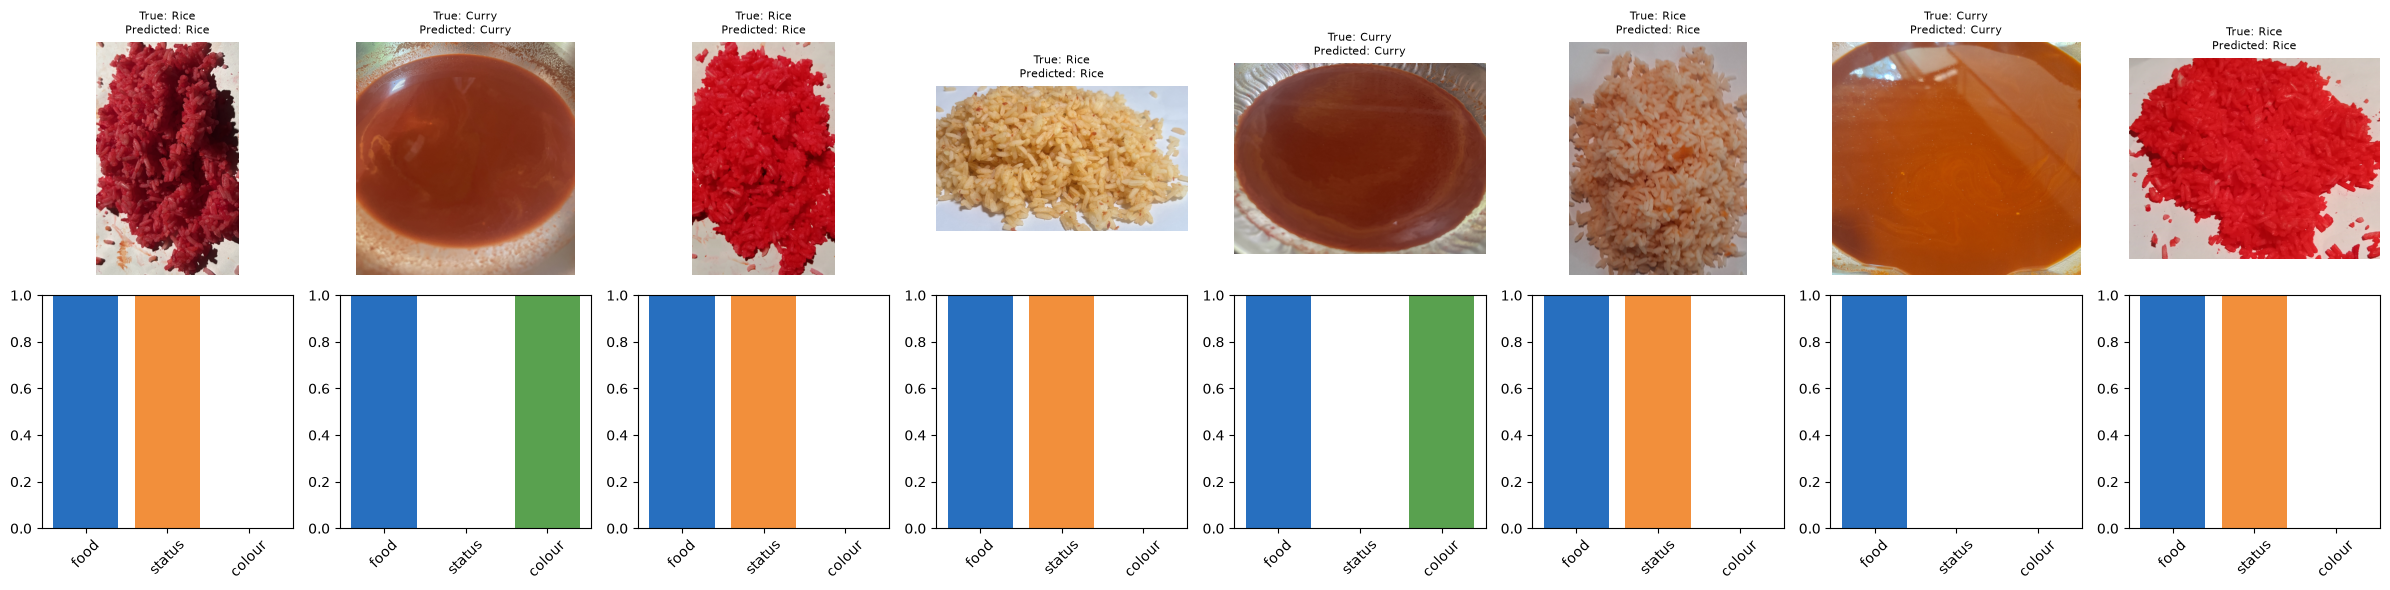

In [196]:
# 16.1 Review incorrect predictions and save representative error images.
if proposed_model is not None:
    wrong = error_table[
        (error_table['true_food'] != error_table['pred_food'])
        | (error_table['true_status'] != error_table['pred_status'])
        | (error_table['true_colour'] != error_table['pred_colour'])
    ].copy()

    print('Incorrect multi-head rows:', len(wrong), '/', len(error_table))
    display(wrong.sort_values('confidence', ascending=False).head(20))

    if len(wrong) > 0:
        sample = wrong.head(min(8, len(wrong)))
        figure, axes = plt.subplots(
            2,
            len(sample),
            figsize=(3 * len(sample), 6),
        )
        axes = np.atleast_2d(axes)

        for index, (_, row) in enumerate(sample.iterrows()):
            image_path = Path(row['image_path'])
            if image_path.exists():
                axes[0, index].imshow(Image.open(image_path).convert('RGB'))
            else:
                axes[0, index].text(0.1, 0.5, 'Image unavailable')

            axes[0, index].axis('off')
            axes[0, index].set_title(
                f"True: {row['true_food']}\nPredicted: {row['pred_food']}",
                fontsize=8,
            )

            head_correctness = [
                row['true_food'] == row['pred_food'],
                row['true_status'] == row['pred_status'],
                row['true_colour'] == row['pred_colour'],
            ]
            axes[1, index].bar(
                ['food', 'status', 'colour'],
                head_correctness,
                color=['#276FBF', '#F28F3B', '#59A14F'],
            )
            axes[1, index].set_ylim(0, 1)
            axes[1, index].tick_params(axis='x', labelrotation=45)

        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / 'representative_errors.png', dpi=160)
        plt.show()

In [197]:
# 16.2 Check whether attention rollout is supported by the trained model.
if proposed_model is not None:
    attention_modules = [
        name
        for name, module in proposed_model.named_modules()
        if 'attention' in name.lower()
    ]

    attention_report = {
        'available_attention_modules': attention_modules,
        'supported_without_model_change': False,
        'note': (
            'Use a Swin implementation that returns attention probabilities '
            'before enabling rollout.'
        ),
    }
    print(attention_report)

{'available_attention_modules': [], 'supported_without_model_change': False, 'note': 'Use a Swin implementation that returns attention probabilities before enabling rollout.'}


In [198]:
# 16.3 Summarise repeated-seed results when independent runs are available.
if 'repeated_runs' not in locals():
    repeated_runs = pd.DataFrame()

if len(repeated_runs) < 2:
    print('At least two independent seeds are required for mean/std reporting.')

if len(repeated_runs) >= 2:
    metric_columns = [
        column
        for column in [
            'food_macro_f1',
            'status_macro_f1',
            'colour_macro_f1',
            'joint_accuracy',
        ]
        if column in repeated_runs.columns
    ]
    repeated_run_summary = repeated_runs[metric_columns].agg(['mean', 'std'])
    display(repeated_run_summary)

At least two independent seeds are required for mean/std reporting.


In [200]:
# 16.4 Report observed findings and study limitations.
if not comparison_table.empty:
    best_row = comparison_table.loc[
        comparison_table['test_joint_accuracy'].idxmax()
    ]
    print(
        f"Observed highest test joint accuracy: {best_row['model']} "
        f"({best_row['test_joint_accuracy']:.4f})."
    )

if comparison_table.empty:
    print(
        'No trained comparison results yet. Set RUN_EXPERIMENTS=True, '
        'confirm Mona dependencies, and execute the training cells.'
    )

print('Outputs are stored in:', OUTPUT_DIR.resolve())
print(
    'Limitations to report: single dataset, finite devices and lights, '
    'possible capture correlation, and no significance claim without '
    'repeated independent seeds.'
)

Observed highest test joint accuracy: efficientnet_v2_s (0.8773).
Outputs are stored in: C:\Destop\final research\research_outputs
Limitations to report: single dataset, finite devices and lights, possible capture correlation, and no significance claim without repeated independent seeds.


# Two-head Food Type + Colouring Level Experiment

This section is a separate implementation for the proposal. It predicts `Food` and ordered `Colouring Level` together. The comparison uses two different pretrained backbones: ResNet18 and MobileNetV3-Small. It does not add the old status or colouring-identity heads.

In [ ]:
# 17.1 Imports, configuration, and reproducibility
import os, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

MT_SEED = 42
MT_FAST_DEBUG = True
MT_EPOCHS = 2 if MT_FAST_DEBUG else 15
MT_BATCH_SIZE = 16
MT_IMAGE_SIZE = 224
MT_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MT_ROOT = Path.cwd()
MT_CSV_PATH = MT_ROOT / 'details.csv'
MT_IMAGE_DIR = MT_ROOT / 'Dataset'

random.seed(MT_SEED)
np.random.seed(MT_SEED)
torch.manual_seed(MT_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MT_SEED)

print('Device:', MT_DEVICE)
print('CSV:', MT_CSV_PATH)
print('Images:', MT_IMAGE_DIR)

In [ ]:
# 17.2 Load metadata and make leakage-aware stratified splits
mt_df = pd.read_csv(MT_CSV_PATH)
required = ['Image Name', 'Food', 'Phone', 'Light', 'Coloring', 'Colouring Level']
missing = sorted(set(required) - set(mt_df.columns))
if missing:
    raise KeyError(f'Missing columns: {missing}')

mt_df = mt_df.copy()
mt_df['image_path'] = mt_df['Image Name'].astype(str).map(
    lambda name: MT_IMAGE_DIR / (name if Path(name).suffix else f'{name}.jpg')
)
mt_df = mt_df[mt_df['image_path'].map(Path.exists)].reset_index(drop=True)
mt_df['food_id'] = pd.Categorical(mt_df['Food']).codes
level_order = {'Low': 0, 'Medium': 1, 'High': 2}
mt_df['colour_level_id'] = mt_df['Colouring Level'].map(level_order)
if mt_df['colour_level_id'].isna().any():
    raise ValueError('Colouring Level must contain only Low, Medium, or High.')
mt_df['split_key'] = mt_df['Food'].astype(str) + '_' + mt_df['Colouring Level'].astype(str)

mt_train, mt_temp = train_test_split(
    mt_df, test_size=0.30, random_state=MT_SEED, stratify=mt_df['split_key']
)
mt_val, mt_test = train_test_split(
    mt_temp, test_size=0.50, random_state=MT_SEED, stratify=mt_temp['split_key']
)
mt_food_labels = sorted(mt_df['Food'].unique())
print('Rows:', len(mt_df), '| train/val/test:', len(mt_train), len(mt_val), len(mt_test))
print('Food classes:', mt_food_labels)
print('Colour level counts:')
display(mt_df['Colouring Level'].value_counts().reindex(level_order.keys()))

In [ ]:
# 17.3 Image dataset and loaders
mt_train_transform = transforms.Compose([
    transforms.Resize((MT_IMAGE_SIZE, MT_IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
mt_eval_transform = transforms.Compose([
    transforms.Resize((MT_IMAGE_SIZE, MT_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class MTFoodDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = Image.open(row['image_path']).convert('RGB')
        return {
            'image': self.transform(image),
            'food': torch.tensor(int(row['food_id']), dtype=torch.long),
            'colour_level': torch.tensor(int(row['colour_level_id']), dtype=torch.long),
        }

mt_train_loader = DataLoader(MTFoodDataset(mt_train, mt_train_transform), MT_BATCH_SIZE, shuffle=True)
mt_val_loader = DataLoader(MTFoodDataset(mt_val, mt_eval_transform), MT_BATCH_SIZE, shuffle=False)
mt_test_loader = DataLoader(MTFoodDataset(mt_test, mt_eval_transform), MT_BATCH_SIZE, shuffle=False)
print('Batches:', len(mt_train_loader), len(mt_val_loader), len(mt_test_loader))

In [ ]:
# 17.4 Two-head model: food classification + ordinal colouring level
class MTOrdinalHead(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.classifier = nn.Linear(in_features, 2)

    def forward(self, features):
        return self.classifier(features)

class MTMultiTaskModel(nn.Module):
    def __init__(self, backbone, feature_dim):
        super().__init__()
        self.backbone = backbone
        self.food_head = nn.Linear(feature_dim, len(mt_food_labels))
        self.colour_level_head = MTOrdinalHead(feature_dim)

    def forward(self, images):
        features = self.backbone(images)
        if features.ndim > 2:
            features = torch.flatten(features, 1)
        return {
            'food': self.food_head(features),
            'colour_level': self.colour_level_head(features),
        }

def mt_weights_or_none(weights_enum):
    try:
        return weights_enum.DEFAULT
    except Exception:
        return None

def build_mt_resnet18():
    weights = mt_weights_or_none(models.ResNet18_Weights)
    network = models.resnet18(weights=weights)
    feature_dim = network.fc.in_features
    network.fc = nn.Identity()
    return MTMultiTaskModel(network, feature_dim).to(MT_DEVICE)

def build_mt_mobilenet_v3_small():
    weights = mt_weights_or_none(models.MobileNet_V3_Small_Weights)
    network = models.mobilenet_v3_small(weights=weights)
    feature_dim = network.classifier[0].in_features
    network.classifier = nn.Identity()
    return MTMultiTaskModel(network, feature_dim).to(MT_DEVICE)

mt_models = {
    'resnet18': build_mt_resnet18,
    'mobilenet_v3_small': build_mt_mobilenet_v3_small,
}
print('Comparison models:', list(mt_models))

In [ ]:
# 17.5 Loss, decoding, training, and evaluation
mt_food_loss = nn.CrossEntropyLoss()
mt_colour_loss = nn.BCEWithLogitsLoss()

def mt_coral_targets(level_ids):
    return torch.stack([level_ids >= 1, level_ids >= 2], dim=1).float()

def mt_decode_colour(logits):
    return (torch.sigmoid(logits) >= 0.5).sum(dim=1).long()

def mt_run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    food_true, food_pred, colour_true, colour_pred = [], [], [], []
    for batch in loader:
        images = batch['image'].to(MT_DEVICE)
        food = batch['food'].to(MT_DEVICE)
        colour = batch['colour_level'].to(MT_DEVICE)
        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = mt_food_loss(outputs['food'], food) + mt_colour_loss(
                outputs['colour_level'], mt_coral_targets(colour)
            )
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(images)
        food_true.extend(food.cpu().numpy())
        food_pred.extend(outputs['food'].argmax(1).detach().cpu().numpy())
        colour_true.extend(colour.cpu().numpy())
        colour_pred.extend(mt_decode_colour(outputs['colour_level']).cpu().numpy())
    metrics = {
        'loss': total_loss / len(loader.dataset),
        'food_accuracy': accuracy_score(food_true, food_pred),
        'food_macro_f1': f1_score(food_true, food_pred, average='macro', zero_division=0),
        'colour_accuracy': accuracy_score(colour_true, colour_pred),
        'colour_mae': mean_absolute_error(colour_true, colour_pred),
        'joint_accuracy': np.mean((np.array(food_true) == np.array(food_pred)) &
                                  (np.array(colour_true) == np.array(colour_pred))),
    }
    return metrics

def train_mt_model(model_name, builder):
    model = builder()
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    history = []
    for epoch in range(MT_EPOCHS):
        train_metrics = mt_run_epoch(model, mt_train_loader, optimizer)
        val_metrics = mt_run_epoch(model, mt_val_loader)
        history.append({'epoch': epoch + 1, **{f'train_{k}': v for k, v in train_metrics.items()},
                        **{f'val_{k}': v for k, v in val_metrics.items()}})
        print(model_name, history[-1])
    test_metrics = mt_run_epoch(model, mt_test_loader)
    return model, pd.DataFrame(history), test_metrics

In [ ]:
# 17.6 Train both different architectures and compare the two heads
mt_results = []
mt_trained = {}
mt_histories = {}
for model_name, builder in mt_models.items():
    model, history, test_metrics = train_mt_model(model_name, builder)
    mt_trained[model_name] = model
    mt_histories[model_name] = history
    mt_results.append({'model': model_name, **{f'test_{k}': v for k, v in test_metrics.items()}})

mt_comparison = pd.DataFrame(mt_results).sort_values('test_joint_accuracy', ascending=False)
display(mt_comparison)

best_mt_name = mt_comparison.iloc[0]['model']
best_mt_model = mt_trained[best_mt_name]
all_true_food, all_pred_food, all_true_colour, all_pred_colour = [], [], [], []
best_mt_model.eval()
with torch.no_grad():
    for batch in mt_test_loader:
        outputs = best_mt_model(batch['image'].to(MT_DEVICE))
        all_true_food.extend(batch['food'].numpy())
        all_pred_food.extend(outputs['food'].argmax(1).cpu().numpy())
        all_true_colour.extend(batch['colour_level'].numpy())
        all_pred_colour.extend(mt_decode_colour(outputs['colour_level']).cpu().numpy())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(all_true_food, all_pred_food), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=mt_food_labels, yticklabels=mt_food_labels)
axes[0].set_title(f'{best_mt_name}: Food type')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
sns.heatmap(confusion_matrix(all_true_colour, all_pred_colour), annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=list(level_order), yticklabels=list(level_order))
axes[1].set_title(f'{best_mt_name}: Colouring level')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
plt.tight_layout(); plt.show()

In [ ]:
# 17.7 Single-image inference for the two prediction heads
def predict_mt_image(image_path, model=best_mt_model):
    image = Image.open(image_path).convert('RGB')
    tensor = mt_eval_transform(image).unsqueeze(0).to(MT_DEVICE)
    model.eval()
    with torch.no_grad():
        outputs = model(tensor)
        food_probabilities = torch.softmax(outputs['food'], dim=1)[0]
        colour_probabilities = torch.sigmoid(outputs['colour_level'])[0]
    food_id = int(food_probabilities.argmax())
    colour_id = int((colour_probabilities >= 0.5).sum())
    return {
        'model': best_mt_name,
        'image': str(image_path),
        'food_prediction': mt_food_labels[food_id],
        'food_confidence': float(food_probabilities[food_id]),
        'colouring_level_prediction': list(level_order)[colour_id],
        'ordinal_probabilities': colour_probabilities.cpu().numpy().round(4).tolist(),
    }

sample_path = mt_test.iloc[0]['image_path']
print(predict_mt_image(sample_path))